###Everything & Then Some: Predicting Repeat Purchases with ML


In [2]:
import sys
import warnings
from collections import namedtuple
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedShuffleSplit, train_test_split
from sklearn.preprocessing import (
    MinMaxScaler, OneHotEncoder, RobustScaler, StandardScaler,
)


RANDOM_STATE = 42
FIGSIZE = (10, 6)
TARGET = 'repeat_purchase_90d'
PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / 'data'


# One warning class is silenced here, on purpose. Read the next cell before
# deciding whether that is ever a reasonable thing to do.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

| column | what it holds | role |
|---|---|---|
| `price` | the asking price in EUR | **target** |
| `Brand` | manufacturer (9 levels) | categorical |
| `model` | model name (308 levels) | categorical, and the survey below is about it |
| `transmission` | manual, automatic, semi-auto, other (4 levels) | categorical |
| `fuelType` | petrol, diesel, hybrid, electric, other (5 levels) | categorical |
| `year` | registration year | numeric, but a year rather than a quantity |
| `mileage` | distance covered | numeric |
| `tax` | annual road tax in EUR | numeric |
| `mpg` | miles per gallon, the maker's figure | numeric |
| `engineSize` | displacement in litres | numeric |
| `paintQuality%` | condition of the paintwork, 0 to 100 | numeric |
| `previousOwners` | how many owners before this sale | numeric count |


Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise

`cars4you_raw.csv` carries one column the finished file does not: `CarID`. It
records nothing about the car. It exists so a cleaning rule can put the rows it
keeps back in the exact order `cars4you.csv` already has, which matters because
every regression week after this one splits the file by row position.

In [3]:
df_train_raw = pd.read_csv(DATA / 'train.csv', index_col='ID')
df_test_raw = pd.read_csv(DATA / 'test.csv', index_col='ID')
df_clientes_raw = pd.read_csv(DATA / 'clientes.csv', index_col='customer_id')

display(pd.DataFrame({name: {'rows': len(df), 'columns': df.shape[1]} for name, df in {'df_train_raw': df_train_raw, 'df_test_raw': df_test_raw, 'df_clientes_raw': df_clientes_raw}.items()}).T)

,rows,columns
df_train_raw,6534,38
df_test_raw,986,37
df_clientes_raw,1143,12


In [4]:
df_train_raw

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.00,57.15,153.099911,4.0,1.0,...,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.00,34.25,472.943134,32.0,1.0,...,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.00,3.60,6.097485,1.0,1.0,...,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.00,0.00,408.167275,9.0,1.0,...,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.00,174.95,485.401864,33.0,1.0,...,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10007670,3023.34,3761.38,2458.00,565.34,0.0,0.00,1303.38,1099.190000,49.0,1.0,...,5548.20,151492,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 3,2016-01-24,-1.579719
10007671,1362.26,1723.10,1107.53,254.73,0.0,34.25,581.32,197.514000,16.0,1.0,...,0.00,975873,Maybe Tomorrow Payment 12,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 1,2021-04-13,-0.576883
10007672,4396.55,3574.43,3574.43,822.12,0.0,0.00,0.00,2075.838024,78.0,1.0,...,27824.52,755628,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 2,2022-03-19,0.528377


In [18]:
print(f"Rows: {df_train_raw.shape[0]:,}")
print(f"Columns: {df_train_raw.shape[1]}")

df_train_raw.info()

Rows: 6,534
Columns: 38
<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure

In [9]:
nulls = df_train_raw.isna().sum()

blank_space = pd.Series(0,index = df_train_raw.columns)

text_columns = df_train_raw.select_dtypes(include=["object", "str"]).columns

for column in text_columns:
    blank_space[column] = (
        df_train_raw[column].str.strip().eq("").fillna(False).sum())

missing_summary = pd.DataFrame({"nulls": nulls, "empty_or_blank_space": blank_space})

missing_summary["total"] = (missing_summary["nulls"] + missing_summary["empty_or_blank_space"])

missing_summary["percentatge"] = (missing_summary["total"] / len(df_train_raw) * 100).round(2)

display(missing_summary.sort_values("total", ascending = False))

,nulls,empty_or_blank_space,total,percentatge
prior_std_gap_days,1478,0,1478,22.62
prior_mean_gap_days,1308,0,1308,20.02
prior_std_purchase_value,1113,0,1113,17.03
prior_mean_purchase_value,862,0,862,13.19
days_since_previous_purchase,861,0,861,13.18
prior_max_purchase_value,668,0,668,10.22
prior_min_purchase_value,668,0,668,10.22
transport_method,261,0,261,3.99
warehouse,260,0,260,3.98
payment_type,260,0,260,3.98


In [12]:
print("Duplicated rows:", df_train_raw.duplicated().sum())

print("ID missing:", df_train_raw.index.isna().sum())
print("ID repeated:", df_train_raw.index.duplicated().sum())



Duplicated rows: 10
ID missing: 0
ID repeated: 0


In [13]:
print("Rows with same exact contect but different ID:", df_train_raw.duplicated().sum())

Rows with same exact contect but different ID: 10


In [15]:
duplicate_rows = df_train_raw[df_train_raw.duplicated(keep=False)]
display(duplicate_rows.sort_values("customer_id"))

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10004187,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,239651,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10005141,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,239651,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002381,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,258332,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10005269,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,258332,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10006618,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,258332,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10006879,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,264090,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10007583,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,264090,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000983,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,334782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003718,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,334782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
duplicate_predictors = duplicate_rows.drop(columns=["customer_id", "repeat_purchase_90d"])

display(duplicate_rows[["customer_id", "repeat_purchase_90d"]].assign(predictors_with_data = duplicate_predictors.notna().sum(axis=1)).sort_values("customer_id"))

,customer_id,repeat_purchase_90d,predictors_with_data
ID,,,
10004187,239651,1,0
10005141,239651,1,0
10002381,258332,1,0
10005269,258332,1,0
10006618,258332,1,0
10006879,264090,0,0
10007583,264090,0,0
10000983,334782,1,0
10003718,334782,1,0


In [18]:
purchase_predictors = df_train_raw.drop(
    columns=["customer_id", "repeat_purchase_90d"]
)

empty_purchase_rows = (
    purchase_predictors
    .replace(r"^\s*$", pd.NA, regex=True)
    .isna()
    .all(axis=1)
)

print("Rows with no predictors:", empty_purchase_rows.sum())
print(f"Percentatge of the dataset: {empty_purchase_rows.mean():.2%}")

Filas sin predictores de la compra: 65
Porcentaje del dataset: 0.99%


In [19]:
# Conservamos las filas excluidas para documentar la decisión.
df_train_no_predictors = df_train_raw.loc[empty_purchase_rows].copy()

# Copia de trabajo; todavía puede contener otros problemas de calidad.
df_train_work = df_train_raw.loc[~empty_purchase_rows].copy()

print("Filas apartadas:", len(df_train_no_predictors))
print("Filas de trabajo:", len(df_train_work))

# Comprobamos si quedan coincidencias entre las filas restantes.
print(
    "Duplicados exactos restantes:",
    df_train_work.duplicated().sum()
)

Filas apartadas: 65
Filas de trabajo: 6469
Duplicados exactos restantes: 0


In [20]:
purchase_dates = pd.to_datetime(
    df_train_work["purchase_date"],
    errors="coerce"
)

print("Fechas originalmente ausentes:",
      df_train_work["purchase_date"].isna().sum())

print("Valores presentes que no se pudieron interpretar:",
      (df_train_work["purchase_date"].notna() & purchase_dates.isna()).sum())

print("Primera fecha:", purchase_dates.min())
print("Última fecha:", purchase_dates.max())

# Comparar el texto original con la interpretación de pandas.
display(
    pd.DataFrame({
        "original": df_train_work["purchase_date"],
        "interpretada": purchase_dates
    }).head(10)
)

Fechas originalmente ausentes: 0
Valores presentes que no se pudieron interpretar: 0
Primera fecha: 2015-07-11 00:00:00
Última fecha: 2025-02-15 00:00:00


,original,interpretada
ID,,
10000000,2024-10-29,2024-10-29
10000001,2017-07-08,2017-07-08
10000002,2019-03-19,2019-03-19
10000003,2018-11-10,2018-11-10
10000004,2021-11-30,2021-11-30
10000005,2023-07-15,2023-07-15
10000007,2016-12-02,2016-12-02
10000009,2021-03-27,2021-03-27
10000011,2017-11-11,2017-11-11


In [22]:
text_columns = df_train_work.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:
    print(f"\n--- {column} ---")

    display(
        df_train_work[column]
        .map(repr)
        .value_counts(dropna=False)
        .rename_axis("value")
        .to_frame("count")
    )


--- payment_type ---


,count
value,
'Maybe Tomorrow Payment 7',4565
'Maybe Tomorrow Payment 12',991
'Maybe Tomorrow Payment 9',502
nan,195
'Maybe Tomorrow Payment 10',134
'Maybe Tomorrow Payment 8',40
'Maybe Tomorrow Payment 2',21
'Maybe Tomorrow Payment 4',9
'Maybe Tomorrow Payment 11',8



--- salesperson ---


,count
value,
'VLOOKUP Master 1',4054
'VLOOKUP Master 4',1461
'VLOOKUP Master 9',384
'VLOOKUP Master 7',201
nan,194
'VLOOKUP Master 2',123
'VLOOKUP Master 3',30
'VLOOKUP Master 6',12
'VLOOKUP Master 5',7



--- commercial_zone ---


...

,count
value,
'Maybe Tomorrow Delivery 72',1119
'Maybe Tomorrow Delivery 61',627
'Maybe Tomorrow Delivery 73',445
'Maybe Tomorrow Delivery 59',373
'Maybe Tomorrow Delivery 80',319
...,...
'Maybe Tomorrow Delivery 55',1
'Maybe Tomorrow Delivery 58',1
'Maybe Tomorrow Delivery 28',1



--- warehouse ---


,count
value,
'Final Excel Warehouse 1',6253
nan,195
'Final Excel Warehouse 3',21



--- document_series ---


,count
value,
'Ctrl Z Series 2',2738
'Ctrl Z Series 3',1903
'Ctrl Z Series 1',1828


In [23]:
with pd.option_context("display.max_rows", None):
    display(
        df_train_work["transport_method"]
        .map(repr)
        .value_counts(dropna=False)
        .rename_axis("value")
        .to_frame("count")
    )

,count
value,
'Maybe Tomorrow Delivery 72',1119
'Maybe Tomorrow Delivery 61',627
'Maybe Tomorrow Delivery 73',445
'Maybe Tomorrow Delivery 59',373
'Maybe Tomorrow Delivery 80',319
'Maybe Tomorrow Delivery 71',301
'Maybe Tomorrow Delivery 40',257
'Maybe Tomorrow Delivery 11',253
'Maybe Tomorrow Delivery 53',247


In [24]:
amount_columns = [
    "Total a Pagar",
    "Total Bruto",
    "Total Liquido",
    "Total Imp_",
    "Total Portes",
    "Total Desc_ Global",
    "Total Desc_ Linha",
    "Custo"
]

amount_summary = (
    df_train_work[amount_columns]
    .describe(percentiles=[0.50, 0.95, 0.99])
    .T
)

amount_summary["missing"] = df_train_work[amount_columns].isna().sum()
amount_summary["zeros"] = df_train_work[amount_columns].eq(0).sum()
amount_summary["negatives"] = df_train_work[amount_columns].lt(0).sum()

display(amount_summary.round(2))

,count,mean,std,min,50%,95%,99%,max,missing,zeros,negatives
Total a Pagar,6469.0,925.56,1335.00,0.93,476.74,3398.77,6543.97,22297.21,0,0,0
Total Bruto,6469.0,886.15,1327.64,0.83,445.74,3251.84,6717.62,21578.28,0,0,0
Total Liquido,6469.0,773.34,1136.36,0.76,389.91,2838.59,5675.70,18127.81,0,0,0
Total Imp_,6469.0,152.22,225.26,0.00,79.74,549.12,1026.79,4169.40,0,213,0
Total Portes,6469.0,1.15,5.84,0.00,0.00,5.75,11.80,181.06,0,5416,0
Total Desc_ Global,6469.0,0.35,5.12,0.00,0.00,0.00,7.85,218.49,0,6359,0
Total Desc_ Linha,6469.0,112.47,289.99,0.00,13.13,540.39,1369.04,4103.44,0,2441,0
Custo,6469.0,328.17,519.51,0.00,152.54,1227.53,2382.10,7427.40,0,486,0


In [25]:
amount_checks = pd.DataFrame(index=df_train_work.index)

amount_checks["payment_difference"] = (
    df_train_work["Total a Pagar"]
    - df_train_work["Total Liquido"]
    - df_train_work["Total Imp_"]
)

amount_checks["net_difference"] = (
    df_train_work["Total Liquido"]
    - (
        df_train_work["Total Bruto"]
        - df_train_work["Total Desc_ Global"]
        - df_train_work["Total Desc_ Linha"]
    )
)

# Tolerancia exploratoria de 5 céntimos para posibles redondeos.
tolerance = 0.05

display(pd.DataFrame({
    "within_tolerance": amount_checks.abs().le(tolerance).sum(),
    "outside_tolerance": amount_checks.abs().gt(tolerance).sum(),
    "max_absolute_difference": amount_checks.abs().max()
}).round(2))

,within_tolerance,outside_tolerance,max_absolute_difference
payment_difference,6469,0,0.0
net_difference,6469,0,0.0


In [26]:
count_columns = [
    "N_ Detalhes",
    "invoice_count_current_purchase"
]

count_summary = df_train_work[count_columns].describe().T

count_summary["missing"] = df_train_work[count_columns].isna().sum()
count_summary["zeros"] = df_train_work[count_columns].eq(0).sum()
count_summary["negatives"] = df_train_work[count_columns].lt(0).sum()

count_summary["non_integer"] = (
    df_train_work[count_columns].notna()
    & df_train_work[count_columns].mod(1).ne(0)
).sum()

display(count_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,missing,zeros,negatives,non_integer
N_ Detalhes,6469.0,21.52,27.71,1.0,4.0,11.0,29.0,423.0,0,0,0,0
invoice_count_current_purchase,6469.0,1.07,0.31,1.0,1.0,1.0,1.0,5.0,0,0,0,0


In [27]:
time_columns = [
    "days_since_previous_purchase",
    "customer_tenure_days",
    "prior_mean_gap_days",
    "prior_std_gap_days"
]

time_summary = (
    df_train_work[time_columns]
    .describe(percentiles=[0.50, 0.95, 0.99])
    .T
)

time_summary["missing"] = df_train_work[time_columns].isna().sum()
time_summary["zeros"] = df_train_work[time_columns].eq(0).sum()
time_summary["negatives"] = df_train_work[time_columns].lt(0).sum()

display(time_summary.round(2))

,count,mean,std,min,50%,95%,99%,max,missing,zeros,negatives
days_since_previous_purchase,5673.0,101.53,165.70,-4.0,57.00,337.00,787.12,3199.00,796,0,16
customer_tenure_days,6469.0,1111.38,923.19,0.0,918.00,2904.00,3318.00,3506.00,0,603,0
prior_mean_gap_days,5226.0,95.88,122.59,-4.0,68.44,263.25,514.10,3199.00,1243,0,16
prior_std_gap_days,5056.0,74.14,101.82,0.0,50.64,220.57,486.34,2212.54,1413,1,0


In [28]:
negative_days = df_train_work["days_since_previous_purchase"].lt(0)
negative_mean_gap = df_train_work["prior_mean_gap_days"].lt(0)

print(
    "Filas con negativos en ambas columnas:",
    (negative_days & negative_mean_gap).sum()
)

display(
    df_train_work.loc[
        negative_days | negative_mean_gap,
        [
            "customer_id",
            "purchase_date",
            "prior_purchase_count",
            "customer_tenure_days",
            "days_since_previous_purchase",
            "prior_mean_gap_days",
            "prior_std_gap_days"
        ]
    ]
)

Filas con negativos en ambas columnas: 0


,customer_id,purchase_date,prior_purchase_count,customer_tenure_days,days_since_previous_purchase,prior_mean_gap_days,prior_std_gap_days
ID,,,,,,,
10000358,861390,2024-06-15,8.0,343.0,-4.0,40.000000,34.535006
10000407,137415,2024-02-18,21.0,897.0,12.0,-4.000000,61.441350
10000574,103940,2019-09-10,115.0,785.0,-4.0,NaN,7.006795
10000592,264531,2024-10-12,12.0,3269.0,-4.0,290.181818,254.423591
10000646,441324,2016-01-24,2.0,140.0,86.0,-4.000000,NaN
10000732,328976,2019-08-03,7.0,497.0,-4.0,79.333333,46.932576
10000799,119885,2021-11-06,11.0,1316.0,-4.0,108.500000,60.266538
10000961,554016,2019-04-14,2.0,28.0,8.0,-4.000000,NaN
10001526,438652,2023-04-11,45.0,2135.0,10.0,-4.000000,37.720872


In [29]:
gap_columns = [
    "days_since_previous_purchase",
    "prior_mean_gap_days"
]

# Registrar los valores inválidos antes de cambiarlos.
negative_gap_values = df_train_work[gap_columns].where(
    df_train_work[gap_columns].lt(0)
).dropna(how="all")

# Sustituir solo los valores negativos por nulos.
df_train_work[gap_columns] = df_train_work[gap_columns].mask(
    df_train_work[gap_columns].lt(0)
)

# Verificar el resultado.
display(pd.DataFrame({
    "negatives_remaining": df_train_work[gap_columns].lt(0).sum(),
    "missing_after": df_train_work[gap_columns].isna().sum()
}))

,negatives_remaining,missing_after
days_since_previous_purchase,0,812
prior_mean_gap_days,0,1259


In [30]:
history_group = pd.cut(
    df_train_work["prior_purchase_count"],
    bins=[-1, 0, 1, 2, float("inf")],
    labels=["0", "1", "2", "3+"]
)

gap_columns = [
    "days_since_previous_purchase",
    "prior_mean_gap_days",
    "prior_std_gap_days"
]

missing_by_history = (
    df_train_work[gap_columns]
    .isna()
    .groupby(history_group, observed=True)
    .mean()
    .mul(100)
)

missing_by_history.insert(
    0,
    "rows",
    df_train_work.groupby(history_group, observed=True).size()
)

display(
    missing_by_history
    .rename_axis("prior_purchases")
    .round(2)
)

,rows,days_since_previous_purchase,prior_mean_gap_days,prior_std_gap_days
prior_purchases,,,,
0,603,100.00,100.00,100.0
1,445,4.94,100.00,100.0
2,365,5.48,6.85,100.0
3+,5056,3.30,3.68,0.0


In [31]:
history_count_columns = [
    "prior_purchase_count",
    "purchase_count_30d",
    "purchase_count_90d",
    "purchase_count_180d",
    "purchase_count_365d"
]

history_counts = df_train_work[history_count_columns]

display(pd.DataFrame({
    "missing": history_counts.isna().sum(),
    "negatives": history_counts.lt(0).sum(),
    "non_integer": (
        history_counts.notna() & history_counts.mod(1).ne(0)
    ).sum(),
    "min": history_counts.min(),
    "max": history_counts.max()
}))

# Una ventana más amplia debería contener al menos tantas compras.
display(pd.Series({
    "30d > 90d": (
        history_counts["purchase_count_30d"]
        > history_counts["purchase_count_90d"]
    ).sum(),
    "90d > 180d": (
        history_counts["purchase_count_90d"]
        > history_counts["purchase_count_180d"]
    ).sum(),
    "180d > 365d": (
        history_counts["purchase_count_180d"]
        > history_counts["purchase_count_365d"]
    ).sum(),
    "365d > total previo": (
        history_counts["purchase_count_365d"]
        > history_counts["prior_purchase_count"]
    ).sum()
}, name="inconsistencias"))

,missing,negatives,non_integer,min,max
prior_purchase_count,0,0,0,0.0,276.0
purchase_count_30d,0,0,0,0.0,11.0
purchase_count_90d,0,0,0,0.0,22.0
purchase_count_180d,0,0,0,0.0,37.0
purchase_count_365d,0,0,0,0.0,60.0


30d > 90d              0
90d > 180d             0
180d > 365d            0
365d > total previo    0
Name: inconsistencias, dtype: int64

In [32]:
history_amount_columns = [
    "prior_total_spend",
    "prior_mean_purchase_value",
    "prior_std_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "spend_30d",
    "spend_90d",
    "spend_180d",
    "spend_365d"
]

history_amounts = df_train_work[history_amount_columns]

history_amount_summary = (
    history_amounts
    .describe(percentiles=[0.50, 0.95, 0.99])
    .T
)

history_amount_summary["missing"] = history_amounts.isna().sum()
history_amount_summary["zeros"] = history_amounts.eq(0).sum()
history_amount_summary["negatives"] = history_amounts.lt(0).sum()

display(history_amount_summary.round(2))

,count,mean,std,min,50%,95%,99%,max,missing,zeros,negatives
prior_total_spend,6469.0,18908.35,31130.87,0.00,6754.31,83478.59,158299.74,2.478651e+05,0,603,0
prior_mean_purchase_value,5672.0,2821825.32,53041566.66,-2478.66,724.90,2564.82,5230.09,1.000000e+09,797,0,16
prior_std_purchase_value,5421.0,737.47,666.26,0.00,569.08,1979.62,3163.45,6.770220e+03,1048,2,0
prior_min_purchase_value,5866.0,185.46,408.40,0.93,64.34,820.70,1905.35,6.298980e+03,603,0,0
prior_max_purchase_value,5866.0,2946.38,5901.55,3.31,1783.24,8050.33,14433.41,2.675262e+05,603,0,0
spend_30d,6469.0,457.14,1191.23,0.00,0.00,2528.62,5396.49,2.229721e+04,0,4342,0
spend_90d,6469.0,1253.53,2347.84,0.00,198.50,5828.66,10875.44,3.023488e+04,0,2889,0
spend_180d,6469.0,2650.60,4020.27,0.00,1117.68,10479.21,19209.80,4.974697e+04,0,1410,0
spend_365d,6274.0,2396534.88,48841133.46,-159115.18,2426.60,22227.60,40876.80,1.000000e+09,195,810,15


In [33]:
# Evitamos dividir por cero cuando no hay compras previas.
previous_count = df_train_work["prior_purchase_count"].where(
    df_train_work["prior_purchase_count"] > 0
)

expected_mean = df_train_work["prior_total_spend"] / previous_count

mean_check = df_train_work[
    [
        "prior_purchase_count",
        "prior_total_spend",
        "prior_mean_purchase_value",
        "prior_min_purchase_value",
        "prior_max_purchase_value"
    ]
].copy()

mean_check["expected_mean"] = expected_mean
mean_check["difference"] = (
    mean_check["prior_mean_purchase_value"] - expected_mean
)

# Solo comparamos filas con ambos valores disponibles.
comparable = (
    mean_check["prior_mean_purchase_value"].notna()
    & mean_check["expected_mean"].notna()
)

inconsistent = comparable & mean_check["difference"].abs().gt(0.05)

print("Filas comparables:", comparable.sum())
print("Diferencias superiores a 0,05:", inconsistent.sum())

display(
    mean_check.loc[inconsistent]
    .sort_values("difference", key=lambda values: values.abs(), ascending=False)
    .head(20)
)

Filas comparables: 5672
Diferencias superiores a 0,05: 78


,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_min_purchase_value,prior_max_purchase_value,expected_mean,difference
ID,,,,,,,
10003702,39.0,5104.07,1.000000e+09,9.59,834.53,130.873590,9.999999e+08
10007157,220.0,47033.52,1.000000e+09,4.54,2306.25,213.788727,9.999998e+08
10006001,2.0,521.57,1.000000e+09,136.38,385.19,260.785000,9.999997e+08
10004113,1.0,390.01,1.000000e+09,390.01,390.01,390.010000,9.999996e+08
10003106,4.0,1943.24,1.000000e+09,144.53,1226.80,485.810000,9.999995e+08
10000304,16.0,8663.31,1.000000e+09,35.61,1130.41,541.456875,9.999995e+08
10005563,11.0,6417.54,1.000000e+09,85.28,1237.31,583.412727,9.999994e+08
10002792,8.0,5074.04,1.000000e+09,182.56,1260.04,634.255000,9.999994e+08
10007199,11.0,8391.76,1.000000e+09,322.05,1167.55,762.887273,9.999992e+08


In [34]:
# Revisar las 78 filas con diferencias detectadas.
mean_review = mean_check.loc[inconsistent].copy()

tolerance = 0.05

mean_review["bounds_available"] = mean_review[
    ["prior_min_purchase_value", "prior_max_purchase_value"]
].notna().all(axis=1)

mean_review["expected_within_bounds"] = (
    mean_review["bounds_available"]
    & (
        mean_review["expected_mean"]
        >= mean_review["prior_min_purchase_value"] - tolerance
    )
    & (
        mean_review["expected_mean"]
        <= mean_review["prior_max_purchase_value"] + tolerance
    )
)

print("Filas revisadas:", len(mean_review))
print(
    "Media calculada dentro del mínimo y máximo:",
    mean_review["expected_within_bounds"].sum()
)

# Mostrar los casos que todavía requieren investigación.
display(
    mean_review.loc[~mean_review["expected_within_bounds"]]
)

Filas revisadas: 78
Media calculada dentro del mínimo y máximo: 78


,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_min_purchase_value,prior_max_purchase_value,expected_mean,difference,bounds_available,expected_within_bounds
ID,,,,,,,,,


In [35]:
# Guardar el valor original y el valor reconstruido.
mean_repair_log = mean_review[
    ["prior_mean_purchase_value", "expected_mean"]
].rename(columns={
    "prior_mean_purchase_value": "original_value",
    "expected_mean": "corrected_value"
}).copy()

# Aplicar la reparación en la copia de trabajo.
df_train_work.loc[
    mean_repair_log.index, "prior_mean_purchase_value"
] = mean_repair_log["corrected_value"]

# Verificar las correcciones.
remaining_difference = (
    df_train_work.loc[
        mean_repair_log.index, "prior_mean_purchase_value"
    ]
    - mean_repair_log["corrected_value"]
).abs()

print("Medias corregidas:", len(mean_repair_log))
print(
    "Correcciones con diferencias superiores a 0,05:",
    remaining_difference.gt(0.05).sum()
)

Medias corregidas: 78
Correcciones con diferencias superiores a 0,05: 0


In [36]:
missing_mean = df_train_work["prior_mean_purchase_value"].isna()
has_history = df_train_work["prior_purchase_count"].gt(0)

print(
    "Medias ausentes sin compras previas:",
    (missing_mean & df_train_work["prior_purchase_count"].eq(0)).sum()
)

missing_mean_review = df_train_work.loc[
    missing_mean & has_history,
    [
        "prior_purchase_count",
        "prior_total_spend",
        "prior_min_purchase_value",
        "prior_max_purchase_value"
    ]
].copy()

missing_mean_review["expected_mean"] = (
    missing_mean_review["prior_total_spend"]
    / missing_mean_review["prior_purchase_count"]
)

missing_mean_review["within_bounds"] = (
    missing_mean_review["expected_mean"].notna()
    & missing_mean_review["prior_min_purchase_value"].notna()
    & missing_mean_review["prior_max_purchase_value"].notna()
    & (
        missing_mean_review["expected_mean"]
        >= missing_mean_review["prior_min_purchase_value"] - 0.05
    )
    & (
        missing_mean_review["expected_mean"]
        <= missing_mean_review["prior_max_purchase_value"] + 0.05
    )
)

print("Medias ausentes con compras previas:", len(missing_mean_review))
print(
    "Reconstrucciones que cumplen los límites:",
    missing_mean_review["within_bounds"].sum()
)

display(
    missing_mean_review.loc[~missing_mean_review["within_bounds"]]
)

Medias ausentes sin compras previas: 603
Medias ausentes con compras previas: 194
Reconstrucciones que cumplen los límites: 194


,prior_purchase_count,prior_total_spend,prior_min_purchase_value,prior_max_purchase_value,expected_mean,within_bounds
ID,,,,,,


In [37]:
# Registrar las reconstrucciones antes de aplicarlas.
mean_fill_log = missing_mean_review.loc[
    missing_mean_review["within_bounds"],
    ["prior_purchase_count", "prior_total_spend", "expected_mean"]
].copy()

# Rellenar únicamente las medias ausentes que hemos comprobado.
df_train_work.loc[
    mean_fill_log.index, "prior_mean_purchase_value"
] = mean_fill_log["expected_mean"]

# Verificar el resultado.
remaining_missing = df_train_work["prior_mean_purchase_value"].isna()

print("Medias reconstruidas:", len(mean_fill_log))
print("Medias todavía ausentes:", remaining_missing.sum())
print(
    "Medias ausentes con compras previas:",
    (
        remaining_missing
        & df_train_work["prior_purchase_count"].gt(0)
    ).sum()
)

Medias reconstruidas: 194
Medias todavía ausentes: 603
Medias ausentes con compras previas: 0


In [38]:
spend_review = df_train_work[
    [
        "prior_purchase_count",
        "prior_total_spend",
        "purchase_count_180d",
        "spend_180d",
        "purchase_count_365d",
        "spend_365d"
    ]
].copy()

tolerance = 0.05

spend_flags = pd.DataFrame({
    "missing": spend_review["spend_365d"].isna(),
    "negative": spend_review["spend_365d"].lt(0),
    "below_spend_180d": (
        spend_review["spend_365d"]
        < spend_review["spend_180d"] - tolerance
    ),
    "above_total_spend": (
        spend_review["spend_365d"]
        > spend_review["prior_total_spend"] + tolerance
    )
})

display(spend_flags.sum().to_frame("rows"))

print(
    "Filas con al menos una señal:",
    spend_flags.any(axis=1).sum()
)

display(
    spend_review.loc[spend_flags.any(axis=1)].head(20)
)

,rows
missing,195
negative,15
below_spend_180d,15
above_total_spend,54


Filas con al menos una señal: 264


,prior_purchase_count,prior_total_spend,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d
ID,,,,,,
10000007,9.0,7472.49,8.0,7327.82,9.0,NaN
10000011,8.0,12487.24,0.0,0.00,3.0,53906.674517
10000053,1.0,351.34,1.0,351.34,1.0,NaN
10000072,9.0,3433.89,1.0,283.10,2.0,11536.764996
10000126,18.0,14148.55,2.0,2421.46,5.0,NaN
10000148,5.0,4884.98,5.0,4884.98,5.0,NaN
10000168,5.0,1726.27,2.0,350.24,2.0,NaN
10000186,106.0,99683.01,20.0,24306.90,35.0,522933.206431
10000212,20.0,8114.25,1.0,323.99,2.0,NaN


In [39]:
rules = {
    "Sin compras en 365 días": (
        spend_review["purchase_count_365d"].eq(0),
        pd.Series(0.0, index=spend_review.index)
    ),
    "Mismas compras en 180 y 365 días": (
        spend_review["purchase_count_365d"].eq(
            spend_review["purchase_count_180d"]
        ),
        spend_review["spend_180d"]
    ),
    "Todo el historial dentro de 365 días": (
        spend_review["purchase_count_365d"].eq(
            spend_review["prior_purchase_count"]
        ),
        spend_review["prior_total_spend"]
    )
}

rule_summary = []

for name, (applies, expected) in rules.items():
    comparable = (
        applies
        & spend_review["spend_365d"].notna()
        & expected.notna()
    )

    difference = (spend_review["spend_365d"] - expected).abs()

    rule_summary.append({
        "rule": name,
        "comparable_rows": comparable.sum(),
        "matches": (comparable & difference.le(0.05)).sum(),
        "mismatches": (comparable & difference.gt(0.05)).sum(),
        "flagged_rows_covered": (
            applies & spend_flags.any(axis=1) & expected.notna()
        ).sum()
    })

display(pd.DataFrame(rule_summary).set_index("rule"))

,comparable_rows,matches,mismatches,flagged_rows_covered
rule,,,,
Sin compras en 365 días,811,810,1,33
Mismas compras en 180 y 365 días,1804,1792,12,80
Todo el historial dentro de 365 días,1725,1703,22,82


In [40]:
# Cada regla propone un importe únicamente donde resulta aplicable.
spend_candidates = pd.DataFrame({
    name: expected.where(applies)
    for name, (applies, expected) in rules.items()
})

has_candidate = spend_candidates.notna().any(axis=1)

# Si se aplican varias reglas, sus propuestas deben coincidir.
candidate_range = (
    spend_candidates.max(axis=1)
    - spend_candidates.min(axis=1)
)

rules_agree = has_candidate & candidate_range.le(0.05)

# Tomamos la primera propuesta disponible, solo si no hay conflicto.
proposed_spend = (
    spend_candidates.bfill(axis=1).iloc[:, 0]
    .where(rules_agree)
)

current_spend = spend_review["spend_365d"]

rule_mismatch = (
    current_spend.notna()
    & proposed_spend.notna()
    & (current_spend - proposed_spend).abs().gt(0.05)
)

previously_flagged = spend_flags.any(axis=1)
needs_review = previously_flagged | rule_mismatch

repairable = needs_review & rules_agree

print("Filas con reglas en conflicto:",
      (has_candidate & ~rules_agree).sum())

print("Discrepancias adicionales detectadas:",
      (rule_mismatch & ~previously_flagged).sum())

print("Filas con propuesta de reconstrucción:",
      repairable.sum())

print("Filas señaladas pendientes de resolver:",
      (needs_review & ~rules_agree).sum())

display(
    spend_candidates.loc[has_candidate & ~rules_agree]
)

Filas con reglas en conflicto: 0
Discrepancias adicionales detectadas: 0
Filas con propuesta de reconstrucción: 108
Filas señaladas pendientes de resolver: 156


,Sin compras en 365 días,Mismas compras en 180 y 365 días,Todo el historial dentro de 365 días
ID,,,


In [41]:
# Comprobar la coherencia de las propuestas.
proposals_valid = (
    proposed_spend.ge(-0.05)
    & proposed_spend.ge(spend_review["spend_180d"] - 0.05)
    & proposed_spend.le(spend_review["prior_total_spend"] + 0.05)
)

assert proposals_valid.loc[repairable].all(), (
    "Hay propuestas incoherentes: revisarlas antes de corregir."
)

# Registrar los valores originales y las reconstrucciones.
spend_repair_log = pd.DataFrame({
    "original_value": df_train_work.loc[repairable, "spend_365d"],
    "corrected_value": proposed_spend.loc[repairable]
})

# Aplicar las reconstrucciones.
df_train_work.loc[
    spend_repair_log.index, "spend_365d"
] = spend_repair_log["corrected_value"]

# Conservar los casos que todavía no sabemos reconstruir.
unresolved_spend = needs_review & ~repairable

print("Valores reconstruidos:", len(spend_repair_log))
print("Casos pendientes:", unresolved_spend.sum())

print(
    "Pendientes que ya eran nulos:",
    df_train_work.loc[unresolved_spend, "spend_365d"].isna().sum()
)

print(
    "Pendientes con un valor presente:",
    df_train_work.loc[unresolved_spend, "spend_365d"].notna().sum()
)

Valores reconstruidos: 108
Casos pendientes: 156
Pendientes que ya eran nulos: 110
Pendientes con un valor presente: 46


In [42]:
# Identificar los valores presentes que siguen siendo inconsistentes.
invalid_spend = (
    unresolved_spend
    & df_train_work["spend_365d"].notna()
)

# Guardar los valores originales para documentar la limpieza.
spend_invalid_log = df_train_work.loc[
    invalid_spend,
    [
        "spend_180d",
        "spend_365d",
        "prior_total_spend",
        "purchase_count_365d"
    ]
].copy()

# Convertir únicamente esas celdas en nulos.
df_train_work.loc[invalid_spend, "spend_365d"] = float("nan")

print("Valores inconsistentes convertidos a nulo:", invalid_spend.sum())
print("Nulos restantes en spend_365d:", df_train_work["spend_365d"].isna().sum())

Valores inconsistentes convertidos a nulo: 46
Nulos restantes en spend_365d: 156


In [43]:
historical_value_checks = pd.DataFrame({
    "min_above_max": (
        df_train_work["prior_min_purchase_value"]
        > df_train_work["prior_max_purchase_value"] + 0.05
    ),
    "mean_below_min": (
        df_train_work["prior_mean_purchase_value"]
        < df_train_work["prior_min_purchase_value"] - 0.05
    ),
    "mean_above_max": (
        df_train_work["prior_mean_purchase_value"]
        > df_train_work["prior_max_purchase_value"] + 0.05
    ),
    "max_above_total": (
        df_train_work["prior_max_purchase_value"]
        > df_train_work["prior_total_spend"] + 0.05
    )
}).fillna(False)

display(historical_value_checks.sum().to_frame("flagged_rows"))

display(
    df_train_work.loc[
        historical_value_checks.any(axis=1),
        [
            "prior_purchase_count",
            "prior_total_spend",
            "prior_mean_purchase_value",
            "prior_min_purchase_value",
            "prior_max_purchase_value"
        ]
    ]
)

,flagged_rows
min_above_max,0
mean_below_min,0
mean_above_max,0
max_above_total,45


,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_min_purchase_value,prior_max_purchase_value
ID,,,,,
10000300,5.0,3456.32,691.264000,87.48,22844.431540
10000853,25.0,40285.74,1611.429600,162.61,55316.611919
10001102,9.0,16658.36,1850.928889,56.33,55269.483555
10001129,5.0,2494.49,498.898000,294.46,21941.361234
10001474,21.0,15632.63,744.410952,17.80,25095.641836
10001601,2.0,39.42,19.710000,3.31,342.485829
10001639,40.0,25784.71,644.617750,19.68,51464.751274
10001749,74.0,9515.10,128.582432,0.93,59422.782539
10001998,7.0,10880.51,1554.358571,56.33,53468.794434


In [44]:
max_review = df_train_work.loc[
    historical_value_checks["max_above_total"],
    [
        "prior_purchase_count",
        "prior_total_spend",
        "prior_min_purchase_value",
        "prior_max_purchase_value"
    ]
].copy()

max_review["proposed_max"] = float("nan")

one_purchase = max_review["prior_purchase_count"].eq(1)
two_purchases = max_review["prior_purchase_count"].eq(2)

max_review.loc[one_purchase, "proposed_max"] = (
    max_review.loc[one_purchase, "prior_total_spend"]
)

max_review.loc[two_purchases, "proposed_max"] = (
    max_review.loc[two_purchases, "prior_total_spend"]
    - max_review.loc[two_purchases, "prior_min_purchase_value"]
)

print("Casos con propuesta:", max_review["proposed_max"].notna().sum())
print("Casos sin reconstrucción:", max_review["proposed_max"].isna().sum())

display(max_review.loc[max_review["proposed_max"].notna()])

Casos con propuesta: 4
Casos sin reconstrucción: 41


,prior_purchase_count,prior_total_spend,prior_min_purchase_value,prior_max_purchase_value,proposed_max
ID,,,,,
10001601,2.0,39.42,3.31,342.485829,36.11
10002363,1.0,643.29,643.29,8094.891964,643.29
10002544,1.0,34.10,34.10,648.994516,34.10
10005354,1.0,248.73,248.73,5549.794793,248.73


In [45]:
# Registrar originales, propuestas y acción aplicada.
max_repair_log = max_review.copy()

max_repair_log["action"] = "converted_to_missing"
max_repair_log.loc[
    max_repair_log["proposed_max"].notna(), "action"
] = "reconstructed"

# proposed_max contiene las 4 reconstrucciones y NaN en los otros 41 casos.
df_train_work.loc[
    max_repair_log.index, "prior_max_purchase_value"
] = max_repair_log["proposed_max"]

# Comprobar el resultado.
print(
    "Máximos reconstruidos:",
    max_repair_log["proposed_max"].notna().sum()
)
print(
    "Máximos inconsistentes convertidos a nulo:",
    max_repair_log["proposed_max"].isna().sum()
)
print(
    "Nulos totales en prior_max_purchase_value:",
    df_train_work["prior_max_purchase_value"].isna().sum()
)
print(
    "Máximos que todavía superan el gasto total:",
    (
        df_train_work["prior_max_purchase_value"]
        > df_train_work["prior_total_spend"] + 0.05
    ).sum()
)

Máximos reconstruidos: 4
Máximos inconsistentes convertidos a nulo: 41
Nulos totales en prior_max_purchase_value: 644
Máximos que todavía superan el gasto total: 0


In [46]:
value_history_group = pd.cut(
    df_train_work["prior_purchase_count"],
    bins=[-1, 0, 1, float("inf")],
    labels=["0", "1", "2+"]
)

value_columns = [
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "prior_std_purchase_value"
]

missing_value_summary = (
    df_train_work[value_columns]
    .isna()
    .groupby(value_history_group, observed=True)
    .sum()
)

missing_value_summary.insert(
    0,
    "rows",
    df_train_work.groupby(value_history_group, observed=True).size()
)

display(
    missing_value_summary.rename_axis("prior_purchases")
)

,rows,prior_min_purchase_value,prior_max_purchase_value,prior_std_purchase_value
prior_purchases,,,,
0,603,603,603,603
1,445,0,0,445
2+,5421,0,41,0


In [47]:
rolling_spend_checks = pd.Series({
    "spend_30d > spend_90d": (
        df_train_work["spend_30d"]
        > df_train_work["spend_90d"] + 0.05
    ).sum(),

    "spend_90d > spend_180d": (
        df_train_work["spend_90d"]
        > df_train_work["spend_180d"] + 0.05
    ).sum(),

    "spend_180d > prior_total_spend": (
        df_train_work["spend_180d"]
        > df_train_work["prior_total_spend"] + 0.05
    ).sum()
}, name="inconsistencies")

display(rolling_spend_checks)

spend_30d > spend_90d             0
spend_90d > spend_180d            0
spend_180d > prior_total_spend    0
Name: inconsistencies, dtype: int64

In [48]:
count_spend_checks = []

for days in [30, 90, 180, 365]:
    count = df_train_work[f"purchase_count_{days}d"]
    spend = df_train_work[f"spend_{days}d"]

    count_spend_checks.append({
        "window_days": days,
        "zero_purchases_nonzero_spend": (
            count.eq(0) & spend.notna() & spend.abs().gt(0.05)
        ).sum(),
        "positive_purchases_zero_spend": (
            count.gt(0) & spend.notna() & spend.eq(0)
        ).sum(),
        "missing_spend": spend.isna().sum()
    })

display(
    pd.DataFrame(count_spend_checks).set_index("window_days")
)

,zero_purchases_nonzero_spend,positive_purchases_zero_spend,missing_spend
window_days,,,
30,0,0,0
90,0,0,0
180,0,0,0
365,0,0,156


In [49]:
target_summary = (
    df_train_work["repeat_purchase_90d"]
    .value_counts(dropna=False)
    .rename_axis("repeat_purchase_90d")
    .to_frame("rows")
)

target_summary["percentage"] = (
    target_summary["rows"] / len(df_train_work) * 100
).round(2)

display(target_summary)

print(
    "Valores distintos de 0 o 1:",
    (
        df_train_work["repeat_purchase_90d"].notna()
        & ~df_train_work["repeat_purchase_90d"].isin([0, 1])
    ).sum()
)

print(
    "Target ausente:",
    df_train_work["repeat_purchase_90d"].isna().sum()
)

,rows,percentage
repeat_purchase_90d,,
1,3621,55.97
0,2848,44.03


Valores distintos de 0 o 1: 0
Target ausente: 0


In [50]:
has_previous_purchase = df_train_work["prior_purchase_count"].gt(0)
no_previous_purchase = df_train_work["prior_purchase_count"].eq(0)

time_checks = pd.DataFrame({
    "previous_gap_exceeds_tenure": (
        df_train_work["days_since_previous_purchase"]
        > df_train_work["customer_tenure_days"]
    ),
    "no_history_but_positive_tenure": (
        no_previous_purchase
        & df_train_work["customer_tenure_days"].gt(0)
    ),
    "has_history_but_zero_tenure": (
        has_previous_purchase
        & df_train_work["customer_tenure_days"].eq(0)
    )
}).fillna(False)

display(time_checks.sum().to_frame("flagged_rows"))

display(
    df_train_work.loc[
        time_checks.any(axis=1),
        [
            "prior_purchase_count",
            "customer_tenure_days",
            "days_since_previous_purchase"
        ]
    ]
)

,flagged_rows
previous_gap_exceeds_tenure,0
no_history_but_positive_tenure,0
has_history_but_zero_tenure,0


,prior_purchase_count,customer_tenure_days,days_since_previous_purchase
ID,,,


In [51]:
missing_after_cleaning = pd.DataFrame({
    "missing": df_train_work.isna().sum(),
    "percentage": df_train_work.isna().mean().mul(100)
})

display(
    missing_after_cleaning
    .loc[missing_after_cleaning["missing"] > 0]
    .sort_values("missing", ascending=False)
    .round(2)
)

print("Filas de trabajo:", len(df_train_work))

,missing,percentage
prior_std_gap_days,1413,21.84
prior_mean_gap_days,1259,19.46
prior_std_purchase_value,1048,16.20
days_since_previous_purchase,812,12.55
prior_max_purchase_value,644,9.96
prior_mean_purchase_value,603,9.32
prior_min_purchase_value,603,9.32
transport_method,196,3.03
payment_type,195,3.01
warehouse,195,3.01


Filas de trabajo: 6469


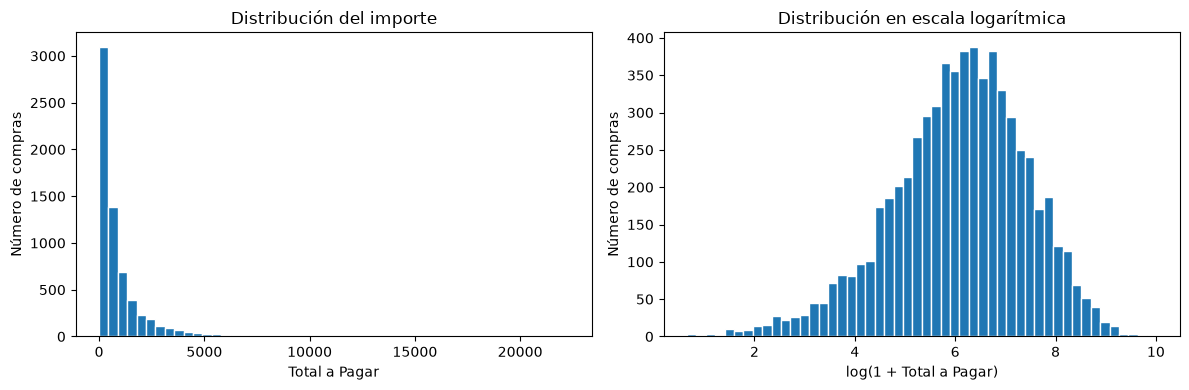

In [52]:
import matplotlib.pyplot as plt
import numpy as np

amount = df_train_work["Total a Pagar"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(amount, bins=50, edgecolor="white")
axes[0].set_title("Distribución del importe")
axes[0].set_xlabel("Total a Pagar")
axes[0].set_ylabel("Número de compras")

axes[1].hist(np.log1p(amount), bins=50, edgecolor="white")
axes[1].set_title("Distribución en escala logarítmica")
axes[1].set_xlabel("log(1 + Total a Pagar)")
axes[1].set_ylabel("Número de compras")

plt.tight_layout()
plt.show()

In [53]:
display(
    df_train_work.nlargest(10, "Total a Pagar")[
        [
            "customer_id",
            "purchase_date",
            "Total a Pagar",
            "Total Liquido",
            "Total Imp_",
            "Custo",
            "N_ Detalhes",
            "invoice_count_current_purchase"
        ]
    ]
)

,customer_id,purchase_date,Total a Pagar,Total Liquido,Total Imp_,Custo,N_ Detalhes,invoice_count_current_purchase
ID,,,,,,,,
10001077,227020,2024-02-24,22297.21,18127.81,4169.40,7052.209816,268.0,1.0
10003479,227020,2024-10-19,18146.78,14753.48,3393.30,5368.567443,199.0,1.0
10005415,755628,2024-03-02,17257.99,14030.89,3227.10,7427.400583,221.0,1.0
10003822,227020,2022-11-12,14433.41,11734.48,2698.93,4656.472745,165.0,1.0
10004393,588588,2017-07-31,12961.99,10538.20,2423.79,179.920000,8.0,1.0
10006444,864223,2023-07-02,12905.74,10492.47,2413.27,6972.197732,126.0,1.0
10006123,227020,2023-09-16,11461.94,9318.65,2143.29,2718.925486,139.0,1.0
10004243,781977,2023-07-29,11457.01,9314.63,2142.38,6897.230661,175.0,4.0
10003225,755628,2022-07-16,11250.72,9146.93,2103.79,4756.185354,156.0,1.0


In [54]:
cost_review = df_train_work[
    ["Total Liquido", "Custo", "N_ Detalhes"]
].copy()

# Cociente auxiliar; no modifica las columnas originales.
cost_review["cost_to_net_ratio"] = (
    cost_review["Custo"]
    / cost_review["Total Liquido"].where(
        df_train_work["Total Liquido"] > 0
    )
)

display(
    cost_review["cost_to_net_ratio"]
    .describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99])
    .to_frame("cost_to_net_ratio")
    .round(4)
)

print("Compras con coste cero:", cost_review["Custo"].eq(0).sum())
print(
    "Compras con coste superior al importe líquido:",
    cost_review["Custo"].gt(cost_review["Total Liquido"]).sum()
)

,cost_to_net_ratio
count,6469.0000
mean,0.4517
std,0.2524
min,0.0000
1%,0.0000
5%,0.0000
50%,0.5024
95%,0.7361
99%,0.9216
max,5.2921


Compras con coste cero: 486
Compras con coste superior al importe líquido: 39


In [55]:
high_cost_rows = cost_review.index[
    cost_review["cost_to_net_ratio"] > 1
]

display(
    df_train_work.loc[
        high_cost_rows,
        [
            "customer_id",
            "purchase_date",
            "Total Bruto",
            "Total Desc_ Global",
            "Total Desc_ Linha",
            "Total Liquido",
            "Custo",
            "N_ Detalhes"
        ]
    ]
    .join(cost_review["cost_to_net_ratio"])
    .sort_values("cost_to_net_ratio", ascending=False)
    .head(10)
)

,customer_id,purchase_date,Total Bruto,Total Desc_ Global,Total Desc_ Linha,Total Liquido,Custo,N_ Detalhes,cost_to_net_ratio
ID,,,,,,,,,
10006171,184050,2018-06-30,336.84,0.0,0.00,336.84,1782.584000,3.0,5.292079
10001422,184050,2019-11-23,342.68,0.0,0.00,342.68,1587.951000,3.0,4.633918
10006431,262827,2017-12-09,384.22,0.0,0.00,384.22,1408.924000,7.0,3.666972
10002155,588588,2019-09-21,602.04,0.0,0.00,602.04,2194.158751,3.0,3.644540
10000282,189146,2017-12-09,71.98,0.0,0.00,71.98,244.233000,3.0,3.393068
10001031,258332,2020-04-19,219.96,0.0,64.20,155.76,505.132600,9.0,3.243019
10001195,820428,2021-12-12,2.76,0.0,0.14,2.62,5.900000,1.0,2.251908
10007625,466120,2018-08-18,174.00,0.0,8.70,165.30,300.000000,1.0,1.814882
10000613,519184,2016-07-24,61.60,0.0,36.96,24.64,44.000000,1.0,1.785714


In [56]:
cost_flags = pd.DataFrame(index=df_train_work.index)

cost_flags["zero_cost"] = df_train_work["Custo"].eq(0)
cost_flags["cost_above_net"] = (
    df_train_work["Custo"] > df_train_work["Total Liquido"]
)

cost_review_log = (
    df_train_work.loc[
        cost_flags.any(axis=1),
        ["customer_id", "purchase_date", "Total Liquido", "Custo"]
    ]
    .join(cost_flags)
)

print("Compras registradas para revisión:", len(cost_review_log))

Compras registradas para revisión: 525


In [57]:
money_check = df_train_work[
    [
        "Total Bruto",
        "Total Desc_ Global",
        "Total Desc_ Linha",
        "Total Liquido",
        "Total Imp_",
        "Total Portes",
        "Total a Pagar"
    ]
].copy()

# Hipótesis 1:
# líquido = bruto - descuento global - descuento de línea
money_check["expected_liquido"] = (
    money_check["Total Bruto"]
    - money_check["Total Desc_ Global"]
    - money_check["Total Desc_ Linha"]
)

money_check["liquido_diff"] = (
    money_check["Total Liquido"]
    - money_check["expected_liquido"]
).abs()

print(
    "Filas donde la fórmula del líquido coincide (tolerancia 0.05):",
    money_check["liquido_diff"].le(0.05).sum()
)

print(
    "Filas donde NO coincide:",
    money_check["liquido_diff"].gt(0.05).sum()
)

display(
    money_check["liquido_diff"]
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .to_frame()
)

Filas donde la fórmula del líquido coincide (tolerancia 0.05): 6469
Filas donde NO coincide: 0


,liquido_diff
count,6.469000e+03
mean,2.519367e-14
std,1.018351e-13
min,0.000000e+00
50%,0.000000e+00
90%,5.684342e-14
95%,1.136868e-13
99%,4.547474e-13
max,3.637979e-12


In [58]:
money_check["expected_total_pagar"] = (
    money_check["Total Liquido"]
    + money_check["Total Imp_"]
    + money_check["Total Portes"]
)

money_check["total_pagar_diff"] = (
    money_check["Total a Pagar"]
    - money_check["expected_total_pagar"]
).abs()

print(
    "Filas donde la fórmula del total a pagar coincide (tolerancia 0.05):",
    money_check["total_pagar_diff"].le(0.05).sum()
)

print(
    "Filas donde NO coincide:",
    money_check["total_pagar_diff"].gt(0.05).sum()
)

display(
    money_check["total_pagar_diff"]
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .to_frame()
)

Filas donde la fórmula del total a pagar coincide (tolerancia 0.05): 5416
Filas donde NO coincide: 1053


,total_pagar_diff
count,6469.000000
mean,1.151427
std,5.844091
min,0.000000
50%,0.000000
90%,4.426000
95%,5.750000
99%,11.800000
max,181.060000


In [59]:
total_mismatch = money_check[
    money_check["total_pagar_diff"] > 0.05
].copy()

display(
    total_mismatch[
        [
            "Total Bruto",
            "Total Desc_ Global",
            "Total Desc_ Linha",
            "Total Liquido",
            "Total Imp_",
            "Total Portes",
            "Total a Pagar",
            "expected_total_pagar",
            "total_pagar_diff"
        ]
    ]
    .sort_values("total_pagar_diff", ascending=False)
    .head(15)
)

,Total Bruto,Total Desc_ Global,Total Desc_ Linha,Total Liquido,Total Imp_,Total Portes,Total a Pagar,expected_total_pagar,total_pagar_diff
ID,,,,,,,,,
10006514,7860.48,0.0,3386.82,4473.66,0.00,181.06,4473.66,4654.72,181.06
10000776,5643.43,0.0,2193.48,3449.95,0.00,159.73,3449.95,3609.68,159.73
10005654,432.00,0.0,0.00,432.00,0.00,150.00,432.00,582.00,150.00
10005170,3250.00,0.0,0.00,3250.00,0.00,150.00,3250.00,3400.00,150.00
10003236,3146.80,0.0,1284.36,1862.44,0.00,142.00,1862.44,2004.44,142.00
10002586,1670.00,0.0,459.00,1211.00,0.00,140.00,1211.00,1351.00,140.00
10002107,12500.00,0.0,3720.00,8780.00,0.00,100.00,8780.00,8880.00,100.00
10000465,286.00,0.0,0.00,286.00,65.78,100.00,351.78,451.78,100.00
10001065,985.50,0.0,366.60,618.90,0.00,69.00,618.90,687.90,69.00


In [60]:
money_check["expected_total_pagar_v2"] = (
    money_check["Total Liquido"]
    + money_check["Total Imp_"]
)

money_check["total_pagar_diff_v2"] = (
    money_check["Total a Pagar"]
    - money_check["expected_total_pagar_v2"]
).abs()

print(
    "Filas donde Total Liquido + Total Imp_ coincide con Total a Pagar:",
    money_check["total_pagar_diff_v2"].le(0.05).sum()
)

print(
    "Filas donde NO coincide:",
    money_check["total_pagar_diff_v2"].gt(0.05).sum()
)

display(
    money_check["total_pagar_diff_v2"]
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .to_frame()
)

Filas donde Total Liquido + Total Imp_ coincide con Total a Pagar: 6469
Filas donde NO coincide: 0


,total_pagar_diff_v2
count,6.469000e+03
mean,2.854662e-14
std,1.192656e-13
min,0.000000e+00
50%,0.000000e+00
90%,5.684342e-14
95%,1.818989e-13
99%,4.547474e-13
max,3.637979e-12


In [61]:
portes_review = df_train_work["Total Portes"].copy()

print("Compras con portes = 0:", portes_review.eq(0).sum())
print("Compras con portes > 0:", portes_review.gt(0).sum())
print("Compras con portes < 0:", portes_review.lt(0).sum())

display(
    portes_review
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame("Total Portes")
)

display(
    df_train_work.nlargest(10, "Total Portes")[
        [
            "customer_id",
            "purchase_date",
            "Total Portes",
            "Total Liquido",
            "Total Imp_",
            "Total a Pagar",
            "N_ Detalhes"
        ]
    ]
)

Compras con portes = 0: 5416
Compras con portes > 0: 1053
Compras con portes < 0: 0


,Total Portes
count,6469.000000
mean,1.151427
std,5.844091
min,0.000000
50%,0.000000
75%,0.000000
90%,4.426000
95%,5.750000
99%,11.800000
max,181.060000


,customer_id,purchase_date,Total Portes,Total Liquido,Total Imp_,Total a Pagar,N_ Detalhes
ID,,,,,,,
10006514,849644,2021-01-11,181.06,4473.66,0.00,4473.66,72.0
10000776,717242,2019-02-23,159.73,3449.95,0.00,3449.95,57.0
10005170,630646,2022-05-31,150.00,3250.00,0.00,3250.00,1.0
10005654,117553,2021-10-23,150.00,432.00,0.00,432.00,4.0
10003236,761979,2024-03-24,142.00,1862.44,0.00,1862.44,39.0
10002586,400536,2018-08-03,140.00,1211.00,0.00,1211.00,3.0
10000465,816330,2017-12-17,100.00,286.00,65.78,351.78,1.0
10002107,400536,2019-09-01,100.00,8780.00,0.00,8780.00,1.0
10001065,744659,2018-04-21,69.00,618.90,0.00,618.90,14.0


In [62]:
tax_review = df_train_work[
    ["Total Liquido", "Total Imp_", "Total a Pagar"]
].copy()

tax_review["tax_rate"] = (
    tax_review["Total Imp_"]
    / tax_review["Total Liquido"].where(
        tax_review["Total Liquido"] > 0
    )
)

print("Compras con impuesto = 0:", tax_review["Total Imp_"].eq(0).sum())
print("Compras con impuesto > 0:", tax_review["Total Imp_"].gt(0).sum())
print("Compras con impuesto < 0:", tax_review["Total Imp_"].lt(0).sum())

display(
    tax_review["tax_rate"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .to_frame("tax_rate")
    .round(4)
)

Compras con impuesto = 0: 213
Compras con impuesto > 0: 6256
Compras con impuesto < 0: 0


,tax_rate
count,6469.0000
mean,0.2151
std,0.0484
min,0.0000
1%,0.0000
5%,0.1206
25%,0.2300
50%,0.2300
75%,0.2300
95%,0.2300


In [63]:
tax_review["tax_rate_rounded"] = tax_review["tax_rate"].round(2)

tax_rate_summary = (
    tax_review["tax_rate_rounded"]
    .value_counts()
    .sort_index()
    .rename_axis("tax_rate")
    .to_frame("purchase_count")
)

tax_rate_summary["percentage"] = (
    tax_rate_summary["purchase_count"]
    / len(tax_review)
    * 100
).round(2)

display(tax_rate_summary)

,purchase_count,percentage
tax_rate,,
0.00,213,3.29
0.05,3,0.05
0.06,55,0.85
0.07,10,0.15
0.08,9,0.14
0.09,14,0.22
0.10,7,0.11
0.11,7,0.11
0.12,8,0.12


In [64]:
zero_tax = df_train_work[
    df_train_work["Total Imp_"].eq(0)
].copy()

print("Compras con impuesto cero:", len(zero_tax))
print(
    "Rango de fechas:",
    zero_tax["purchase_date"].min(),
    "→",
    zero_tax["purchase_date"].max()
)
print(
    "Clientes distintos:",
    zero_tax["customer_id"].nunique()
)

display(
    zero_tax[
        [
            "customer_id",
            "purchase_date",
            "document_series",
            "Total Bruto",
            "Total Desc_ Linha",
            "Total Liquido",
            "Total Imp_",
            "Total a Pagar",
            "N_ Detalhes"
        ]
    ].head(15)
)

Compras con impuesto cero: 213
Rango de fechas: 2015-08-15 00:00:00 → 2024-12-28 00:00:00
Clientes distintos: 39


,customer_id,purchase_date,document_series,Total Bruto,Total Desc_ Linha,Total Liquido,Total Imp_,Total a Pagar,N_ Detalhes
ID,,,,,,,,,
10000134,770471,2021-09-06,Ctrl Z Series 2,4096.22,437.69,3658.53,0.0,3658.53,44.0
10000149,702119,2024-09-20,Ctrl Z Series 2,3802.81,982.95,2819.86,0.0,2819.86,85.0
10000211,683049,2023-04-25,Ctrl Z Series 2,8822.96,1384.96,7438.00,0.0,7438.00,88.0
10000213,807493,2023-06-10,Ctrl Z Series 2,1517.16,338.80,1178.36,0.0,1178.36,35.0
10000252,531725,2022-12-18,Ctrl Z Series 2,2833.10,840.43,1992.67,0.0,1992.67,28.0
10000256,880399,2019-09-06,Ctrl Z Series 1,1952.10,581.79,1370.31,0.0,1370.31,49.0
10000260,683049,2022-10-04,Ctrl Z Series 2,1324.34,0.00,1324.34,0.0,1324.34,2.0
10000328,851871,2024-10-28,Ctrl Z Series 2,4833.26,1222.51,3610.75,0.0,3610.75,87.0
10000379,807493,2021-12-17,Ctrl Z Series 2,1529.32,456.45,1072.87,0.0,1072.87,26.0


In [65]:
zero_tax_by_series = (
    df_train_work
    .groupby("document_series")
    .agg(
        total_purchases=("Total Imp_", "size"),
        zero_tax_purchases=("Total Imp_", lambda x: x.eq(0).sum())
    )
)

zero_tax_by_series["zero_tax_percentage"] = (
    zero_tax_by_series["zero_tax_purchases"]
    / zero_tax_by_series["total_purchases"]
    * 100
).round(2)

display(
    zero_tax_by_series
    .sort_values("zero_tax_purchases", ascending=False)
)

,total_purchases,zero_tax_purchases,zero_tax_percentage
document_series,,,
Ctrl Z Series 2,2738,174,6.36
Ctrl Z Series 1,1828,28,1.53
Ctrl Z Series 3,1903,11,0.58


In [66]:
global_discount_review = df_train_work["Total Desc_ Global"].copy()

print("Descuento global = 0:", global_discount_review.eq(0).sum())
print("Descuento global > 0:", global_discount_review.gt(0).sum())
print("Descuento global < 0:", global_discount_review.lt(0).sum())

display(
    global_discount_review
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame("Total Desc_ Global")
)

display(
    df_train_work.nlargest(10, "Total Desc_ Global")[
        [
            "customer_id",
            "purchase_date",
            "Total Bruto",
            "Total Desc_ Global",
            "Total Desc_ Linha",
            "Total Liquido",
            "Total a Pagar"
        ]
    ]
)

Descuento global = 0: 6359
Descuento global > 0: 110
Descuento global < 0: 0


,Total Desc_ Global
count,6469.000000
mean,0.349907
std,5.116564
min,0.000000
50%,0.000000
75%,0.000000
90%,0.000000
95%,0.000000
99%,7.846400
max,218.490000


,customer_id,purchase_date,Total Bruto,Total Desc_ Global,Total Desc_ Linha,Total Liquido,Total a Pagar
ID,,,,,,,
10007082,113110,2015-07-11,436.99,218.49,0.00,218.50,268.76
10004096,529466,2023-03-18,3688.52,184.40,0.47,3503.65,4309.49
10001765,529466,2024-06-15,2714.40,135.72,0.00,2578.68,3171.78
10000690,952237,2022-02-26,4037.80,115.88,175.00,3746.92,4608.71
10002919,473647,2023-08-01,2715.14,97.14,772.26,1845.74,1845.74
10005523,666120,2016-10-16,2987.25,89.62,0.00,2897.63,3564.08
10002808,667800,2021-03-06,1313.69,65.68,0.00,1248.01,1535.05
10006205,248016,2016-01-10,4318.99,57.62,1437.80,2823.57,3472.99
10003711,847373,2015-08-23,112.24,56.12,0.00,56.12,69.03


In [67]:
line_discount_review = df_train_work["Total Desc_ Linha"].copy()

print("Descuento de línea = 0:", line_discount_review.eq(0).sum())
print("Descuento de línea > 0:", line_discount_review.gt(0).sum())
print("Descuento de línea < 0:", line_discount_review.lt(0).sum())

display(
    line_discount_review
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame("Total Desc_ Linha")
)

display(
    df_train_work.nlargest(10, "Total Desc_ Linha")[
        [
            "customer_id",
            "purchase_date",
            "Total Bruto",
            "Total Desc_ Global",
            "Total Desc_ Linha",
            "Total Liquido",
            "N_ Detalhes"
        ]
    ]
)

Descuento de línea = 0: 2441
Descuento de línea > 0: 4028
Descuento de línea < 0: 0


,Total Desc_ Linha
count,6469.000000
mean,112.466414
std,289.986307
min,0.000000
50%,13.130000
75%,92.280000
90%,297.286000
95%,540.394000
99%,1369.040000
max,4103.440000


,customer_id,purchase_date,Total Bruto,Total Desc_ Global,Total Desc_ Linha,Total Liquido,N_ Detalhes
ID,,,,,,,
10001172,531725,2023-08-01,12260.66,0.0,4103.44,8157.22,108.0
10003996,807493,2020-10-02,13371.49,0.0,3794.51,9576.98,243.0
10002107,400536,2019-09-01,12500.00,0.0,3720.00,8780.00,1.0
10004460,770941,2021-09-08,9323.35,0.0,3704.89,5618.46,60.0
10004243,781977,2023-07-29,12937.14,0.0,3622.51,9314.63,175.0
10001077,227020,2024-02-24,21578.28,0.0,3450.47,18127.81,268.0
10002779,531725,2022-09-20,10423.98,0.0,3434.18,6989.80,89.0
10006514,849644,2021-01-11,7860.48,0.0,3386.82,4473.66,72.0
10002580,531725,2024-04-13,10482.95,0.0,3235.74,7247.21,69.0


In [68]:
discount_review = df_train_work[
    [
        "Total Bruto",
        "Total Desc_ Global",
        "Total Desc_ Linha"
    ]
].copy()

discount_review["total_discount"] = (
    discount_review["Total Desc_ Global"]
    + discount_review["Total Desc_ Linha"]
)

discount_review["discount_rate"] = (
    discount_review["total_discount"]
    / discount_review["Total Bruto"].where(
        discount_review["Total Bruto"] > 0
    )
)

display(
    discount_review["discount_rate"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame("discount_rate")
    .round(4)
)

print(
    "Compras con descuento > 50%:",
    discount_review["discount_rate"].gt(0.50).sum()
)

print(
    "Compras con descuento >= 100%:",
    discount_review["discount_rate"].ge(1).sum()
)

,discount_rate
count,6469.0000
mean,0.1107
std,0.1354
min,0.0000
1%,0.0000
5%,0.0000
25%,0.0000
50%,0.0470
75%,0.2000
90%,0.3005


Compras con descuento > 50%: 68
Compras con descuento >= 100%: 0


In [69]:
high_discount = (
    df_train_work
    .assign(
        total_discount=(
            df_train_work["Total Desc_ Global"]
            + df_train_work["Total Desc_ Linha"]
        ),
        discount_rate=(
            (
                df_train_work["Total Desc_ Global"]
                + df_train_work["Total Desc_ Linha"]
            )
            / df_train_work["Total Bruto"]
        )
    )
    .query("discount_rate > 0.50")
    .sort_values("discount_rate", ascending=False)
)

display(
    high_discount[
        [
            "customer_id",
            "purchase_date",
            "Total Bruto",
            "Total Desc_ Global",
            "Total Desc_ Linha",
            "total_discount",
            "Total Liquido",
            "discount_rate",
            "N_ Detalhes"
        ]
    ].head(15)
)

,customer_id,purchase_date,Total Bruto,Total Desc_ Global,Total Desc_ Linha,total_discount,Total Liquido,discount_rate,N_ Detalhes
ID,,,,,,,,,
10005284,923177,2018-01-19,42.75,0.0,41.67,41.67,1.08,0.974737,10.0
10002480,320681,2018-12-04,225.60,0.0,177.81,177.81,47.79,0.788165,29.0
10006168,974136,2016-11-06,83.20,0.0,63.60,63.60,19.60,0.764423,5.0
10004149,806571,2017-12-09,94.85,0.0,67.91,67.91,26.94,0.715973,2.0
10001967,430570,2017-12-09,92.05,0.0,63.76,63.76,28.29,0.692667,4.0
10002965,789016,2017-12-09,117.48,0.0,76.96,76.96,40.52,0.655090,6.0
10001342,320681,2017-12-09,120.85,0.0,78.31,78.31,42.54,0.647993,3.0
10000734,165185,2021-08-31,55.30,0.0,35.06,35.06,20.24,0.633996,8.0
10007434,519184,2016-11-08,698.41,0.0,427.05,427.05,271.36,0.611460,27.0


In [70]:
details_review = df_train_work["N_ Detalhes"].copy()

print("Valores nulos:", details_review.isna().sum())
print("Valores = 0:", details_review.eq(0).sum())
print("Valores < 0:", details_review.lt(0).sum())

display(
    details_review
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame("N_ Detalhes")
)

display(
    df_train_work.nlargest(10, "N_ Detalhes")[
        [
            "customer_id",
            "purchase_date",
            "N_ Detalhes",
            "Total Bruto",
            "Total Liquido",
            "Total a Pagar"
        ]
    ]
)

Valores nulos: 0
Valores = 0: 0
Valores < 0: 0


,N_ Detalhes
count,6469.000000
mean,21.524501
std,27.713419
min,1.000000
50%,11.000000
75%,29.000000
90%,56.000000
95%,75.000000
99%,128.000000
max,423.000000


,customer_id,purchase_date,N_ Detalhes,Total Bruto,Total Liquido,Total a Pagar
ID,,,,,,
10006855,488020,2017-07-22,423.0,6022.05,5693.56,6991.26
10002061,488020,2017-03-19,309.0,3275.02,3224.69,3934.28
10001077,227020,2024-02-24,268.0,21578.28,18127.81,22297.21
10003996,807493,2020-10-02,243.0,13371.49,9576.98,9576.98
10002202,229396,2016-03-20,233.0,3203.10,3203.10,3939.81
10005415,755628,2024-03-02,221.0,14570.54,14030.89,17257.99
10003479,227020,2024-10-19,199.0,17644.61,14753.48,18146.78
10003698,488020,2022-07-30,199.0,4560.50,4406.16,5419.58
10005016,807493,2021-08-28,198.0,13008.46,10082.56,10082.56


In [71]:
invoice_count_review = df_train_work[
    "invoice_count_current_purchase"
].copy()

print("Valores nulos:", invoice_count_review.isna().sum())
print("Valores = 0:", invoice_count_review.eq(0).sum())
print("Valores < 0:", invoice_count_review.lt(0).sum())

display(
    invoice_count_review
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("invoice_count_current_purchase")
    .to_frame("purchase_count")
)

display(
    df_train_work.nlargest(
        10,
        "invoice_count_current_purchase"
    )[
        [
            "customer_id",
            "purchase_date",
            "invoice_count_current_purchase",
            "N_ Detalhes",
            "Total Bruto",
            "Total Liquido",
            "Total a Pagar"
        ]
    ]
)

Valores nulos: 0
Valores = 0: 0
Valores < 0: 0


,purchase_count
invoice_count_current_purchase,
1.0,6116
2.0,312
3.0,14
4.0,21
5.0,6


,customer_id,purchase_date,invoice_count_current_purchase,N_ Detalhes,Total Bruto,Total Liquido,Total a Pagar
ID,,,,,,,
10000431,781977,2020-10-10,5.0,51.0,1809.48,1427.75,1756.14
10000902,781977,2020-05-01,5.0,100.0,5596.16,4522.66,5562.87
10001317,781977,2019-09-21,5.0,34.0,346.34,340.17,418.41
10003818,781977,2019-12-07,5.0,125.0,3237.10,2562.35,3151.69
10005657,821421,2020-09-18,5.0,5.0,1529.50,1529.50,1874.50
10006913,781977,2019-08-24,5.0,117.0,4408.36,3370.81,4146.09
10000224,781977,2020-12-05,4.0,161.0,7631.34,5341.95,6570.60
10000225,781977,2019-07-06,4.0,68.0,2233.50,1518.78,1868.09
10000284,781977,2024-11-09,4.0,90.0,4145.34,2984.68,3671.16


In [72]:
categorical_cols = [
    "payment_type",
    "salesperson",
    "commercial_zone",
    "transport_method",
    "warehouse",
    "document_series"
]

categorical_summary = pd.DataFrame({
    "n_unique": df_train_work[categorical_cols].nunique(dropna=True),
    "n_missing": df_train_work[categorical_cols].isna().sum(),
    "missing_pct": (
        df_train_work[categorical_cols].isna().mean() * 100
    ).round(2)
})

display(categorical_summary)

,n_unique,n_missing,missing_pct
payment_type,9,195,3.01
salesperson,9,194,3.00
commercial_zone,5,0,0.00
transport_method,80,196,3.03
warehouse,2,195,3.01
document_series,3,0,0.00


In [73]:
payment_type_summary = (
    df_train_work["payment_type"]
    .fillna("MISSING")
    .value_counts()
    .rename_axis("payment_type")
    .to_frame("count")
)

payment_type_summary["percentage"] = (
    payment_type_summary["count"]
    / len(df_train_work)
    * 100
).round(2)

display(payment_type_summary)

,count,percentage
payment_type,,
Maybe Tomorrow Payment 7,4565,70.57
Maybe Tomorrow Payment 12,991,15.32
Maybe Tomorrow Payment 9,502,7.76
MISSING,195,3.01
Maybe Tomorrow Payment 10,134,2.07
Maybe Tomorrow Payment 8,40,0.62
Maybe Tomorrow Payment 2,21,0.32
Maybe Tomorrow Payment 4,9,0.14
Maybe Tomorrow Payment 11,8,0.12


In [74]:
missing_categorical_cols = [
    "payment_type",
    "salesperson",
    "transport_method",
    "warehouse"
]

missing_pattern = (
    df_train_work[missing_categorical_cols]
    .isna()
    .value_counts()
    .rename("count")
    .reset_index()
)

display(missing_pattern)

,payment_type,salesperson,transport_method,warehouse,count
0,False,False,False,False,5720
1,False,False,True,False,183
2,True,False,False,False,182
3,False,True,False,False,178
4,False,False,False,True,175
5,False,True,False,True,7
6,True,False,False,True,7
7,False,False,True,True,6
8,False,True,True,False,5
9,True,True,False,False,4


In [75]:
payment_missing_by_series = (
    df_train_work
    .assign(
        payment_type_missing=df_train_work["payment_type"].isna()
    )
    .groupby("document_series")
    .agg(
        total_purchases=("payment_type_missing", "size"),
        missing_payment_type=("payment_type_missing", "sum")
    )
)

payment_missing_by_series["missing_percentage"] = (
    payment_missing_by_series["missing_payment_type"]
    / payment_missing_by_series["total_purchases"]
    * 100
).round(2)

display(payment_missing_by_series)

,total_purchases,missing_payment_type,missing_percentage
document_series,,,
Ctrl Z Series 1,1828,52,2.84
Ctrl Z Series 2,2738,89,3.25
Ctrl Z Series 3,1903,54,2.84


In [76]:
salesperson_summary = (
    df_train_work["salesperson"]
    .fillna("MISSING")
    .value_counts()
    .rename_axis("salesperson")
    .to_frame("count")
)

salesperson_summary["percentage"] = (
    salesperson_summary["count"]
    / len(df_train_work)
    * 100
).round(2)

display(salesperson_summary)

,count,percentage
salesperson,,
VLOOKUP Master 1,4054,62.67
VLOOKUP Master 4,1461,22.58
VLOOKUP Master 9,384,5.94
VLOOKUP Master 7,201,3.11
MISSING,194,3.00
VLOOKUP Master 2,123,1.90
VLOOKUP Master 3,30,0.46
VLOOKUP Master 6,12,0.19
VLOOKUP Master 5,7,0.11


In [77]:
commercial_zone_summary = (
    df_train_work["commercial_zone"]
    .value_counts()
    .rename_axis("commercial_zone")
    .to_frame("count")
)

commercial_zone_summary["percentage"] = (
    commercial_zone_summary["count"]
    / len(df_train_work)
    * 100
).round(2)

display(commercial_zone_summary)

,count,percentage
commercial_zone,,
Decorative Dashboard Zone 4,6260,96.77
Decorative Dashboard Zone 2,151,2.33
Decorative Dashboard Zone 3,56,0.87
Decorative Dashboard Zone 6,1,0.02
Decorative Dashboard Zone 7,1,0.02


In [78]:
warehouse_summary = (
    df_train_work["warehouse"]
    .fillna("MISSING")
    .value_counts()
    .rename_axis("warehouse")
    .to_frame("count")
)

warehouse_summary["percentage"] = (
    warehouse_summary["count"]
    / len(df_train_work)
    * 100
).round(2)

display(warehouse_summary)

,count,percentage
warehouse,,
Final Excel Warehouse 1,6253,96.66
MISSING,195,3.01
Final Excel Warehouse 3,21,0.32


In [79]:
document_series_summary = (
    df_train_work["document_series"]
    .value_counts()
    .rename_axis("document_series")
    .to_frame("count")
)

document_series_summary["percentage"] = (
    document_series_summary["count"]
    / len(df_train_work)
    * 100
).round(2)

display(document_series_summary)

,count,percentage
document_series,,
Ctrl Z Series 2,2738,42.32
Ctrl Z Series 3,1903,29.42
Ctrl Z Series 1,1828,28.26


In [80]:
transport_counts = (
    df_train_work["transport_method"]
    .value_counts(dropna=True)
)

print("Categorías totales:", len(transport_counts))
print("Categorías con 1 sola compra:", (transport_counts == 1).sum())
print("Categorías con <= 5 compras:", (transport_counts <= 5).sum())
print("Categorías con <= 10 compras:", (transport_counts <= 10).sum())
print("Categorías con <= 50 compras:", (transport_counts <= 50).sum())

print("\nTop 15 categorías:")
display(
    transport_counts
    .head(15)
    .rename_axis("transport_method")
    .to_frame("count")
)

Categorías totales: 80
Categorías con 1 sola compra: 26
Categorías con <= 5 compras: 37
Categorías con <= 10 compras: 42
Categorías con <= 50 compras: 58

Top 15 categorías:


,count
transport_method,
Maybe Tomorrow Delivery 72,1119
Maybe Tomorrow Delivery 61,627
Maybe Tomorrow Delivery 73,445
Maybe Tomorrow Delivery 59,373
Maybe Tomorrow Delivery 80,319
Maybe Tomorrow Delivery 71,301
Maybe Tomorrow Delivery 40,257
Maybe Tomorrow Delivery 11,253
Maybe Tomorrow Delivery 53,247


In [81]:
transport_original = df_train_work["transport_method"]

transport_clean = (
    transport_original
    .str.strip()
    .str.lower()
)

print(
    "Categorías originales:",
    transport_original.nunique(dropna=True)
)

print(
    "Categorías después de normalizar texto:",
    transport_clean.nunique(dropna=True)
)

print(
    "Categorías que desaparecerían por diferencias de formato:",
    transport_original.nunique(dropna=True)
    - transport_clean.nunique(dropna=True)
)

Categorías originales: 80
Categorías después de normalizar texto: 80
Categorías que desaparecerían por diferencias de formato: 0


In [82]:
target_summary = (
    df_train_work[TARGET]
    .value_counts(dropna=False)
    .rename_axis(TARGET)
    .to_frame("count")
)

target_summary["percentage"] = (
    target_summary["count"]
    / len(df_train_work)
    * 100
).round(2)

display(target_summary)

,count,percentage
repeat_purchase_90d,,
1,3621,55.97
0,2848,44.03


In [83]:
prior_count_by_target = (
    df_train_work
    .groupby(TARGET)["prior_purchase_count"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90]
    )
)

display(prior_count_by_target)

,count,mean,std,min,25%,50%,75%,90%,max
repeat_purchase_90d,,,,,,,,,
0,2848.0,10.539326,14.128140,0.0,2.0,6.0,15.0,26.3,276.0
1,3621.0,33.618614,47.281537,0.0,6.0,17.0,40.0,79.0,275.0


In [84]:
historical_cols = [
    "days_since_previous_purchase",
    "customer_tenure_days",
    "prior_purchase_count",
    "prior_total_spend",
    "prior_mean_purchase_value",
    "prior_mean_gap_days",
    "purchase_count_30d",
    "spend_30d",
    "purchase_count_90d",
    "spend_90d",
    "purchase_count_180d",
    "spend_180d",
    "purchase_count_365d",
    "spend_365d"
]

historical_medians_by_target = (
    df_train_work
    .groupby(TARGET)[historical_cols]
    .median()
    .T
)

historical_medians_by_target.columns = ["target_0", "target_1"]

display(historical_medians_by_target)

,target_0,target_1
days_since_previous_purchase,105.000000,37.000000
customer_tenure_days,781.000000,1032.000000
prior_purchase_count,6.000000,17.000000
prior_total_spend,3246.525000,12098.990000
prior_mean_purchase_value,626.171167,777.195792
prior_mean_gap_days,101.750000,55.757576
purchase_count_30d,0.000000,0.000000
spend_30d,0.000000,0.000000
purchase_count_90d,0.000000,1.000000
spend_90d,0.000000,746.190000


In [85]:
historical_corr = (
    df_train_work[historical_cols]
    .corr(method="spearman")
    .round(2)
)

display(historical_corr)

,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_mean_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d
days_since_previous_purchase,1.00,0.04,-0.38,-0.32,-0.03,0.47,-0.84,-0.81,-0.86,-0.80,-0.75,-0.62,-0.61,-0.49
customer_tenure_days,0.04,1.00,0.79,0.72,0.12,0.16,0.06,0.08,0.15,0.19,0.27,0.33,0.40,0.43
prior_purchase_count,-0.38,0.79,1.00,0.90,0.13,-0.52,0.38,0.36,0.52,0.50,0.67,0.65,0.80,0.74
prior_total_spend,-0.32,0.72,0.90,1.00,0.57,-0.44,0.31,0.34,0.46,0.54,0.61,0.76,0.73,0.88
prior_mean_purchase_value,-0.03,0.12,0.13,0.57,1.00,-0.04,-0.07,0.06,-0.01,0.27,0.06,0.51,0.10,0.61
prior_mean_gap_days,0.47,0.16,-0.52,-0.44,-0.04,1.00,-0.43,-0.38,-0.58,-0.49,-0.69,-0.55,-0.74,-0.57
purchase_count_30d,-0.84,0.06,0.38,0.31,-0.07,-0.43,1.00,0.97,0.73,0.66,0.62,0.50,0.53,0.42
spend_30d,-0.81,0.08,0.36,0.34,0.06,-0.38,0.97,1.00,0.69,0.68,0.58,0.53,0.49,0.45
purchase_count_90d,-0.86,0.15,0.52,0.46,-0.01,-0.58,0.73,0.69,1.00,0.91,0.83,0.68,0.72,0.59
spend_90d,-0.80,0.19,0.50,0.54,0.27,-0.49,0.66,0.68,0.91,1.00,0.75,0.78,0.65,0.68


In [86]:
target_correlations = (
    df_train_work[
        historical_cols + [TARGET]
    ]
    .corr(method="spearman")[TARGET]
    .drop(TARGET)
    .sort_values(key=abs, ascending=False)
    .to_frame("spearman_with_target")
)

display(target_correlations)

,spearman_with_target
purchase_count_365d,0.437012
prior_mean_gap_days,-0.420404
purchase_count_180d,0.406150
purchase_count_90d,0.392761
spend_365d,0.391062
spend_180d,0.369532
spend_90d,0.359129
prior_purchase_count,0.345631
prior_total_spend,0.331624
days_since_previous_purchase,-0.315347


In [87]:
current_purchase_cols = [
    "Total a Pagar",
    "Total Bruto",
    "Total Liquido",
    "Total Imp_",
    "Total Portes",
    "Total Desc_ Global",
    "Total Desc_ Linha",
    "Custo",
    "N_ Detalhes",
    "invoice_count_current_purchase"
]

current_purchase_target_corr = (
    df_train_work[
        current_purchase_cols + [TARGET]
    ]
    .corr(method="spearman")[TARGET]
    .drop(TARGET)
    .sort_values(key=abs, ascending=False)
    .to_frame("spearman_with_target")
)

display(current_purchase_target_corr)

,spearman_with_target
Total Desc_ Linha,0.196787
Total Imp_,0.080788
Total Bruto,0.078003
invoice_count_current_purchase,0.058124
Total a Pagar,0.052770
Total Liquido,0.049657
Total Desc_ Global,-0.042204
N_ Detalhes,-0.029201
Total Portes,0.021527
Custo,-0.013269


In [88]:
payment_target = (
    df_train_work
    .assign(
        payment_type_analysis=df_train_work["payment_type"].fillna("MISSING")
    )
    .groupby("payment_type_analysis")
    .agg(
        purchases=(TARGET, "size"),
        repeat_rate=(TARGET, "mean")
    )
    .sort_values("purchases", ascending=False)
)

payment_target["repeat_rate"] = (
    payment_target["repeat_rate"] * 100
).round(2)

display(payment_target)

,purchases,repeat_rate
payment_type_analysis,,
Maybe Tomorrow Payment 7,4565,52.73
Maybe Tomorrow Payment 12,991,54.29
Maybe Tomorrow Payment 9,502,95.02
MISSING,195,56.41
Maybe Tomorrow Payment 10,134,40.30
Maybe Tomorrow Payment 8,40,32.50
Maybe Tomorrow Payment 2,21,52.38
Maybe Tomorrow Payment 4,9,44.44
Maybe Tomorrow Payment 11,8,62.50


In [89]:
payment_time_check = (
    df_train_work
    .assign(
        payment_type_analysis=df_train_work["payment_type"].fillna("MISSING"),
        purchase_year=df_train_work["purchase_date"].dt.year
    )
    .groupby("payment_type_analysis")
    .agg(
        purchases=(TARGET, "size"),
        first_year=("purchase_year", "min"),
        last_year=("purchase_year", "max"),
        n_years=("purchase_year", "nunique")
    )
    .sort_values("purchases", ascending=False)
)

display(payment_time_check)

,purchases,first_year,last_year,n_years
payment_type_analysis,,,,
Maybe Tomorrow Payment 7,4565,2015,2025,11
Maybe Tomorrow Payment 12,991,2015,2025,11
Maybe Tomorrow Payment 9,502,2016,2025,10
MISSING,195,2015,2025,11
Maybe Tomorrow Payment 10,134,2019,2025,7
Maybe Tomorrow Payment 8,40,2018,2025,7
Maybe Tomorrow Payment 2,21,2023,2025,3
Maybe Tomorrow Payment 4,9,2023,2024,2
Maybe Tomorrow Payment 11,8,2022,2024,3


In [90]:
salesperson_target = (
    df_train_work
    .assign(
        salesperson_analysis=df_train_work["salesperson"].fillna("MISSING")
    )
    .groupby("salesperson_analysis")
    .agg(
        purchases=(TARGET, "size"),
        repeat_rate=(TARGET, "mean")
    )
    .sort_values("purchases", ascending=False)
)

salesperson_target["repeat_rate"] = (
    salesperson_target["repeat_rate"] * 100
).round(2)

display(salesperson_target)

,purchases,repeat_rate
salesperson_analysis,,
VLOOKUP Master 1,4054,62.43
VLOOKUP Master 4,1461,39.43
VLOOKUP Master 9,384,54.69
VLOOKUP Master 7,201,48.26
MISSING,194,59.79
VLOOKUP Master 2,123,60.16
VLOOKUP Master 3,30,36.67
VLOOKUP Master 6,12,0.00
VLOOKUP Master 5,7,42.86


In [91]:
commercial_zone_target = (
    df_train_work
    .groupby("commercial_zone")
    .agg(
        purchases=(TARGET, "size"),
        repeat_rate=(TARGET, "mean")
    )
    .sort_values("purchases", ascending=False)
)

commercial_zone_target["repeat_rate"] = (
    commercial_zone_target["repeat_rate"] * 100
).round(2)

display(commercial_zone_target)

,purchases,repeat_rate
commercial_zone,,
Decorative Dashboard Zone 4,6260,56.53
Decorative Dashboard Zone 2,151,41.06
Decorative Dashboard Zone 3,56,35.71
Decorative Dashboard Zone 6,1,0.00
Decorative Dashboard Zone 7,1,0.00


In [92]:
warehouse_target = (
    df_train_work
    .assign(
        warehouse_analysis=df_train_work["warehouse"].fillna("MISSING")
    )
    .groupby("warehouse_analysis")
    .agg(
        purchases=(TARGET, "size"),
        repeat_rate=(TARGET, "mean")
    )
    .sort_values("purchases", ascending=False)
)

warehouse_target["repeat_rate"] = (
    warehouse_target["repeat_rate"] * 100
).round(2)

display(warehouse_target)

,purchases,repeat_rate
warehouse_analysis,,
Final Excel Warehouse 1,6253,55.65
MISSING,195,63.59
Final Excel Warehouse 3,21,80.95


In [93]:
document_series_target = (
    df_train_work
    .groupby("document_series")
    .agg(
        purchases=(TARGET, "size"),
        repeat_rate=(TARGET, "mean")
    )
    .sort_values("purchases", ascending=False)
)

document_series_target["repeat_rate"] = (
    document_series_target["repeat_rate"] * 100
).round(2)

display(document_series_target)

,purchases,repeat_rate
document_series,,
Ctrl Z Series 2,2738,55.81
Ctrl Z Series 3,1903,56.07
Ctrl Z Series 1,1828,56.13


In [94]:
transport_target = (
    df_train_work
    .assign(
        transport_analysis=df_train_work["transport_method"].fillna("MISSING")
    )
    .groupby("transport_analysis")
    .agg(
        purchases=(TARGET, "size"),
        repeat_rate=(TARGET, "mean")
    )
)

transport_target["repeat_rate"] = (
    transport_target["repeat_rate"] * 100
).round(2)

transport_target_reliable = (
    transport_target
    .query("purchases >= 50")
    .sort_values("repeat_rate", ascending=False)
)

display(transport_target_reliable)

,purchases,repeat_rate
transport_analysis,,
Maybe Tomorrow Delivery 11,253,98.02
Maybe Tomorrow Delivery 22,50,86.00
Maybe Tomorrow Delivery 51,182,66.48
Maybe Tomorrow Delivery 53,247,66.40
Maybe Tomorrow Delivery 41,169,66.27
Maybe Tomorrow Delivery 80,319,64.58
Maybe Tomorrow Delivery 35,122,63.11
Maybe Tomorrow Delivery 61,627,60.13
Maybe Tomorrow Delivery 44,72,59.72


In [95]:
customer_counts = df_train_work["customer_id"].value_counts()

print("Número de compras:", len(df_train_work))
print("Clientes únicos:", df_train_work["customer_id"].nunique())
print("Compras medias por cliente:", round(customer_counts.mean(), 2))
print("Mediana de compras por cliente:", customer_counts.median())
print("Máximo de compras de un cliente:", customer_counts.max())
print(
    "Clientes con más de una compra:",
    (customer_counts > 1).sum()
)
print(
    "Porcentaje de filas pertenecientes a clientes repetidos:",
    round(
        df_train_work["customer_id"]
        .isin(customer_counts[customer_counts > 1].index)
        .mean() * 100,
        2
    ),
    "%"
)

Número de compras: 6469
Clientes únicos: 607
Compras medias por cliente: 10.66
Mediana de compras por cliente: 4.0
Máximo de compras de un cliente: 276
Clientes con más de una compra: 450
Porcentaje de filas pertenecientes a clientes repetidos: 97.57 %


In [96]:
target_by_year = (
    df_train_work
    .assign(year=df_train_work["purchase_date"].dt.year)
    .groupby("year")
    .agg(
        purchases=(TARGET, "size"),
        repeat_rate=(TARGET, "mean")
    )
)

target_by_year["repeat_rate"] = (
    target_by_year["repeat_rate"] * 100
).round(2)

display(target_by_year)

,purchases,repeat_rate
year,,
2015,335,53.43
2016,420,51.43
2017,670,63.28
2018,716,53.77
2019,646,52.17
2020,670,59.40
2021,782,54.86
2022,628,48.09
2023,767,58.15


In [97]:
last_months_target = (
    df_train_work
    .assign(month=df_train_work["purchase_date"].dt.to_period("M"))
    .groupby("month")
    .agg(
        purchases=(TARGET, "size"),
        repeat_rate=(TARGET, "mean")
    )
    .tail(12)
)

last_months_target["repeat_rate"] = (
    last_months_target["repeat_rate"] * 100
).round(2)

print("Primera fecha:", df_train_work["purchase_date"].min())
print("Última fecha:", df_train_work["purchase_date"].max())

display(last_months_target)

Primera fecha: 2015-07-11 00:00:00
Última fecha: 2025-02-15 00:00:00


,purchases,repeat_rate
month,,
2024-03,102,43.14
2024-04,40,60.00
2024-05,25,72.00
2024-06,63,52.38
2024-07,85,50.59
2024-08,49,77.55
2024-09,42,73.81
2024-10,69,76.81
2024-11,87,42.53


In [98]:
check_target = df_train_work[
    df_train_work["purchase_date"]
    <= df_train_work["purchase_date"].max() - pd.Timedelta(days=90)
].copy()

next_purchase_date = (
    df_train_work
    .sort_values(["customer_id", "purchase_date"])
    .groupby("customer_id")["purchase_date"]
    .shift(-1)
)

check_target["next_purchase_date"] = next_purchase_date.loc[check_target.index]

check_target["target_reconstructed"] = (
    (check_target["next_purchase_date"] - check_target["purchase_date"]).dt.days <= 90
).astype(int)

print("Filas comprobables:", len(check_target))
print(
    "Coincidencias:",
    (check_target[TARGET] == check_target["target_reconstructed"]).sum()
)
print(
    "Discrepancias:",
    (check_target[TARGET] != check_target["target_reconstructed"]).sum()
)

Filas comprobables: 6283
Coincidencias: 6267
Discrepancias: 16


In [99]:
target_mismatches = check_target.loc[
    check_target[TARGET] != check_target["target_reconstructed"],
    [
        "customer_id",
        "purchase_date",
        "next_purchase_date",
        TARGET,
        "target_reconstructed"
    ]
].copy()

target_mismatches["days_to_next_purchase"] = (
    target_mismatches["next_purchase_date"]
    - target_mismatches["purchase_date"]
).dt.days

print(
    target_mismatches[
        [TARGET, "target_reconstructed"]
    ].value_counts()
)

display(
    target_mismatches.sort_values(
        ["customer_id", "purchase_date"]
    )
)

repeat_purchase_90d  target_reconstructed
1                    0                       16
Name: count, dtype: int64


,customer_id,purchase_date,next_purchase_date,repeat_purchase_90d,target_reconstructed,days_to_next_purchase
ID,,,,,,
10006669,122356,2018-07-31,2018-10-30,1,0,91.0
10005271,151492,2017-04-21,2017-07-29,1,0,99.0
10004055,230585,2019-04-09,2019-12-01,1,0,236.0
10001555,255774,2022-01-29,2023-07-02,1,0,519.0
10002395,262488,2021-07-03,2022-07-02,1,0,364.0
10007430,334782,2016-12-12,2017-04-02,1,0,111.0
10001613,388138,2021-02-27,2021-06-26,1,0,119.0
10007199,427118,2018-03-30,2018-07-21,1,0,113.0
10002811,438652,2024-06-29,2024-10-12,1,0,105.0


In [100]:
purchase_check = (
    df_train_work
    .sort_values(["customer_id", "purchase_date"])
    [["customer_id", "purchase_date", "days_since_previous_purchase"]]
    .copy()
)

purchase_check["previous_visible_date"] = (
    purchase_check
    .groupby("customer_id")["purchase_date"]
    .shift(1)
)

purchase_check["days_since_previous_visible"] = (
    purchase_check["purchase_date"]
    - purchase_check["previous_visible_date"]
).dt.days

comparison = purchase_check[
    purchase_check["previous_visible_date"].notna()
    & purchase_check["days_since_previous_purchase"].notna()
]

print("Comparaciones posibles:", len(comparison))

print(
    "Coinciden:",
    (
        comparison["days_since_previous_visible"]
        == comparison["days_since_previous_purchase"]
    ).sum()
)

print(
    "No coinciden:",
    (
        comparison["days_since_previous_visible"]
        != comparison["days_since_previous_purchase"]
    ).sum()
)

Comparaciones posibles: 5654
Coinciden: 5603
No coinciden: 51


In [101]:
last_visible_purchase = (
    df_train_work
    .sort_values(["customer_id", "purchase_date"])
    .groupby("customer_id")
    .tail(1)
)

print("Clientes:", len(last_visible_purchase))

print(
    last_visible_purchase[TARGET]
    .value_counts()
    .sort_index()
)

print(
    "\nTasa de target=1 en la última compra visible:",
    round(last_visible_purchase[TARGET].mean() * 100, 2),
    "%"
)

Clientes: 607
repeat_purchase_90d
0    566
1     41
Name: count, dtype: int64

Tasa de target=1 en la última compra visible: 6.75 %


In [102]:
print(df_train_work["random_noise"].describe())

print(
    "\nSpearman con el target:",
    round(
        df_train_work[["random_noise", TARGET]]
        .corr(method="spearman")
        .loc["random_noise", TARGET],
        4
    )
)

count    6469.000000
mean       -0.022140
std         1.001054
min        -3.529210
25%        -0.677770
50%        -0.045714
75%         0.641711
max         4.151241
Name: random_noise, dtype: float64

Spearman con el target: -0.0082


In [104]:
print("Nombre del índice:", df_train_work.index.name)
print("Número de filas:", len(df_train_work))
print("Valores únicos del índice:", df_train_work.index.nunique())
print("Índices duplicados:", df_train_work.index.duplicated().sum())

Nombre del índice: ID
Número de filas: 6469
Valores únicos del índice: 6469
Índices duplicados: 0


In [105]:
target_by_month = (
    df_train_work
    .assign(month=df_train_work["purchase_date"].dt.month)
    .groupby("month")
    .agg(
        purchases=(TARGET, "size"),
        repeat_rate=(TARGET, "mean")
    )
)

target_by_month["repeat_rate"] = (
    target_by_month["repeat_rate"] * 100
).round(2)

display(target_by_month)

,purchases,repeat_rate
month,,
1,444,68.92
2,260,61.92
3,876,43.84
4,442,51.13
5,196,72.45
6,311,60.45
7,874,48.86
8,525,60.95
9,436,69.27


In [106]:
target_by_weekday = (
    df_train_work
    .assign(
        weekday=df_train_work["purchase_date"].dt.day_name()
    )
    .groupby("weekday")
    .agg(
        purchases=(TARGET, "size"),
        repeat_rate=(TARGET, "mean")
    )
)

target_by_weekday["repeat_rate"] = (
    target_by_weekday["repeat_rate"] * 100
).round(2)

display(
    target_by_weekday.sort_values(
        "repeat_rate",
        ascending=False
    )
)

,purchases,repeat_rate
weekday,,
Monday,630,67.14
Friday,811,64.36
Tuesday,683,63.10
Thursday,24,62.50
Sunday,1022,55.97
Wednesday,84,54.76
Saturday,3215,50.14


In [107]:
weekday_year = (
    df_train_work
    .assign(
        year=df_train_work["purchase_date"].dt.year,
        weekday=df_train_work["purchase_date"].dt.day_name()
    )
    .pivot_table(
        index="year",
        columns="weekday",
        values=TARGET,
        aggfunc=["size", "mean"]
    )
)

display(weekday_year.round(3))

size                                                     mean  \
weekday Friday Monday Saturday Sunday Thursday Tuesday Wednesday Friday   
year                                                                      
2015      52.0   40.0     74.0   91.0      1.0    65.0      12.0  0.654   
2016      57.0   32.0     68.0  229.0      3.0    24.0       7.0  0.614   
2017      63.0   51.0    264.0  187.0      7.0    70.0      28.0  0.810   
2018     119.0   65.0    369.0  100.0      NaN    57.0       6.0  0.538   
2019      55.0   52.0    420.0   58.0      NaN    57.0       4.0  0.727   
2020      96.0   66.0    391.0   32.0      NaN    78.0       7.0  0.625   
2021      77.0   86.0    466.0   72.0      NaN    76.0       5.0  0.623   
2022      61.0   85.0    361.0   65.0      2.0    47.0       7.0  0.607   
2023      77.0   72.0    424.0   88.0      NaN   102.0       4.0  0.740   
2024     141.0   65.0    353.0   93.0      NaN   101.0       4.0  0.617   
2025      13.0   16.0     25.0    7.0     11.0     6.0       NaN  0.692   

                                                           
weekday Monday Saturday Sunday Thursday Tuesday Wednesday  
year                                                       
2015     0.600    0.365  0.626    0.000   0.431     0.750  
2016     0.594    0.618  0.428    0.667   0.667     0.571  
2017     0.608    0.629  0.636    0.429   0.657     0.286  
2018     0.662    0.512  0.500      NaN   0.667     0.167  
2019     0.731    0.421  0.603      NaN   0.772     0.750  
2020     0.727    0.537  0.750      NaN   0.641     0.857  
2021     0.674    0.502  0.542      NaN   0.605     0.800  
2022     0.729    0.385  0.369    1.000   0.681     0.857  
2023     0.681    0.519  0.602      NaN   0.627     0.750  
2024     0.662    0.550  0.720      NaN   0.624     0.500  
2025     0.500    0.560  0.857    0.727   0.667       NaN

In [108]:
month_year = (
    df_train_work
    .assign(
        year=df_train_work["purchase_date"].dt.year,
        month=df_train_work["purchase_date"].dt.month
    )
    .pivot_table(
        index="year",
        columns="month",
        values=TARGET,
        aggfunc="mean"
    )
)

display((month_year * 100).round(1))

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2015,NaN,NaN,NaN,NaN,NaN,NaN,53.3,70.0,58.1,41.8,42.5,62.1
2016,69.2,56.0,26.7,88.9,71.4,50.0,41.6,75.0,75.0,63.6,52.3,52.8
2017,78.4,40.0,48.1,43.1,80.0,46.7,62.5,65.1,89.3,82.0,57.6,60.0
2018,60.3,55.0,37.7,52.5,77.8,74.3,59.2,40.0,71.4,76.1,45.7,52.1
2019,73.2,50.0,39.4,42.3,60.0,80.8,42.5,66.2,70.6,59.6,33.1,70.5
2020,68.4,75.9,54.3,48.8,66.7,52.3,44.9,42.9,68.3,75.6,72.2,50.0
2021,82.9,81.8,43.0,55.8,73.0,64.7,51.8,50.0,63.0,57.6,45.1,54.9
2022,60.5,52.2,43.7,56.9,61.5,62.5,38.5,56.8,54.3,34.4,35.3,61.1
2023,59.7,44.8,54.9,48.7,90.0,58.9,43.7,67.2,75.0,71.1,47.8,75.0


In [109]:
monthly_target_trend = (
    df_train_work
    .set_index("purchase_date")
    .resample("MS")[TARGET]
    .agg(["size", "mean"])
)

monthly_target_trend["repeat_rate_12m"] = (
    monthly_target_trend["mean"]
    .rolling(12, min_periods=6)
    .mean()
    * 100
)

display(
    monthly_target_trend[
        ["size", "repeat_rate_12m"]
    ].tail(36).round(2)
)

,size,repeat_rate_12m
purchase_date,,
2022-03-01,87,56.02
2022-04-01,58,56.11
2022-05-01,26,55.16
2022-06-01,32,54.98
2022-07-01,104,53.86
2022-08-01,44,54.43
2022-09-01,46,53.71
2022-10-01,61,51.78
2022-11-01,68,50.96


In [110]:
print("Columnas actuales:", len(df_train_work.columns))

for i, col in enumerate(df_train_work.columns, start=1):
    print(f"{i:02d}. {col}")

Columnas actuales: 38
01. Total a Pagar
02. Total Bruto
03. Total Liquido
04. Total Imp_
05. Total Portes
06. Total Desc_ Global
07. Total Desc_ Linha
08. Custo
09. N_ Detalhes
10. invoice_count_current_purchase
11. repeat_purchase_90d
12. days_since_previous_purchase
13. customer_tenure_days
14. prior_purchase_count
15. prior_total_spend
16. prior_mean_purchase_value
17. prior_std_purchase_value
18. prior_min_purchase_value
19. prior_max_purchase_value
20. prior_mean_gap_days
21. prior_std_gap_days
22. purchase_count_30d
23. spend_30d
24. purchase_count_90d
25. spend_90d
26. purchase_count_180d
27. spend_180d
28. purchase_count_365d
29. spend_365d
30. customer_id
31. payment_type
32. salesperson
33. commercial_zone
34. transport_method
35. warehouse
36. document_series
37. purchase_date
38. random_noise


In [111]:
remaining_history_cols = [
    "prior_std_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "prior_std_gap_days"
]

print("=== SPEARMAN CON EL TARGET ===")

display(
    df_train_work[
        remaining_history_cols + [TARGET]
    ]
    .corr(method="spearman")[TARGET]
    .drop(TARGET)
    .sort_values(key=abs, ascending=False)
)

print("\n=== MEDIANAS POR TARGET ===")

display(
    df_train_work
    .groupby(TARGET)[remaining_history_cols]
    .median()
    .T
)

=== SPEARMAN CON EL TARGET ===


prior_std_gap_days         -0.315142
prior_max_purchase_value    0.255921
prior_min_purchase_value   -0.235476
prior_std_purchase_value    0.167135
Name: repeat_purchase_90d, dtype: float64


=== MEDIANAS POR TARGET ===


repeat_purchase_90d,0,1
prior_std_purchase_value,426.382545,650.037943
prior_min_purchase_value,88.110000,45.510000
prior_max_purchase_value,1335.460000,2306.250000
prior_std_gap_days,65.063511,43.615046


In [112]:
customers = pd.read_csv("../data/clientes.csv")

print("Shape:", customers.shape)
print("Customer IDs únicos:", customers["customer_id"].nunique())
print("Customer IDs duplicados:", customers["customer_id"].duplicated().sum())

display(
    pd.DataFrame({
        "dtype": customers.dtypes,
        "missing": customers.isna().sum(),
        "missing_pct": customers.isna().mean().mul(100).round(2),
        "n_unique": customers.nunique(dropna=True)
    })
)

Shape: (1143, 13)
Customer IDs únicos: 1143
Customer IDs duplicados: 0


,dtype,missing,missing_pct,n_unique
customer_id,int64,0,0.00,1143
country_or_region,str,0,0.00,11
commercial_region,str,114,9.97,37
island,str,578,50.57,10
municipality,str,159,13.91,183
city,str,546,47.77,417
postal_area,str,71,6.21,271
postal_code,str,170,14.87,828
street,str,598,52.32,511
address,str,6,0.52,1120


In [113]:
for col in [
    "country_or_region",
    "commercial_region",
    "island"
]:
    print(f"\n=== {col} ===")

    counts = (
        customers[col]
        .fillna("MISSING")
        .value_counts(dropna=False)
    )

    display(
        pd.DataFrame({
            "count": counts,
            "pct": (counts / len(customers) * 100).round(2)
        })
    )


=== country_or_region ===


,count,pct
country_or_region,,
Country CT10: Land of The Final Version,1079,94.40
Country CT5: Land of The Final Version,49,4.29
Country CT4: Land of The Final Version,4,0.35
Country CT6: Land of The Final Version,3,0.26
Country CT7: Land of The Final Version,2,0.17
Country CT11: Land of The Final Version,1,0.09
Country CT9: Land of The Final Version,1,0.09
Country CT2: Land of The Final Version,1,0.09
Country CT1: Land of The Final Version,1,0.09



=== commercial_region ===


,count,pct
commercial_region,,
Region RG17: We Will See Later,519,45.41
MISSING,114,9.97
Region RG23: We Will See Later,63,5.51
Region RG18: We Will See Later,59,5.16
Region RG29: We Will See Later,46,4.02
Region RG31: We Will See Later,41,3.59
Region RG27: We Will See Later,39,3.41
Region RG28: We Will See Later,36,3.15
Region RG32: We Will See Later,31,2.71



=== island ===


,count,pct
island,,
MISSING,578,50.57
Island IS7: The Pivot Archipelago,133,11.64
Island IS8: The Pivot Archipelago,90,7.87
Island IS4: The Pivot Archipelago,88,7.70
Island IS6: The Pivot Archipelago,81,7.09
Island IS1: The Pivot Archipelago,43,3.76
Island IS9: The Pivot Archipelago,43,3.76
Island IS5: The Pivot Archipelago,37,3.24
Island IS2: The Pivot Archipelago,26,2.27


In [114]:
customer_cols = [
    "customer_id",
    "country_or_region",
    "commercial_region",
    "island",
    "customer_since_year"
]

df_train_customers = df_train_work.merge(
    customers[customer_cols],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Filas antes:", len(df_train_work))
print("Filas después:", len(df_train_customers))

print("\nMissing después del join:")
display(
    df_train_customers[customer_cols[1:]]
    .isna()
    .sum()
)

Filas antes: 6469
Filas después: 6469

Missing después del join:


country_or_region         0
commercial_region        35
island                 2189
customer_since_year       0
dtype: int64

In [115]:
df_train_customers["customer_age_years"] = (
    df_train_customers["purchase_date"].dt.year
    - df_train_customers["customer_since_year"]
)

print("=== CUSTOMER AGE YEARS ===")

display(
    df_train_customers["customer_age_years"].describe()
)

print(
    "\nValores negativos:",
    (df_train_customers["customer_age_years"] < 0).sum()
)

print(
    "Missing:",
    df_train_customers["customer_age_years"].isna().sum()
)

=== CUSTOMER AGE YEARS ===


count    6469.000000
mean        3.611687
std         2.722889
min         0.000000
25%         1.000000
50%         3.000000
75%         6.000000
max        10.000000
Name: customer_age_years, dtype: float64


Valores negativos: 0
Missing: 0


In [116]:
age_comparison = df_train_customers[
    [
        "customer_age_years",
        "customer_tenure_days",
        TARGET
    ]
]

print("=== SPEARMAN CORRELATION ===")
display(
    age_comparison.corr(method="spearman").round(3)
)

print("\n=== MEDIAN BY TARGET ===")
display(
    df_train_customers
    .groupby(TARGET)[
        ["customer_age_years", "customer_tenure_days"]
    ]
    .median()
)

=== SPEARMAN CORRELATION ===


,customer_age_years,customer_tenure_days,repeat_purchase_90d
customer_age_years,1.000,0.917,0.108
customer_tenure_days,0.917,1.000,0.120
repeat_purchase_90d,0.108,0.120,1.000



=== MEDIAN BY TARGET ===


,customer_age_years,customer_tenure_days
repeat_purchase_90d,,
0,3.0,781.0
1,3.0,1032.0


In [117]:
for col in [
    "country_or_region",
    "commercial_region",
    "island"
]:
    print(f"\n=== {col} ===")

    result = (
        df_train_customers
        .assign(**{col: df_train_customers[col].fillna("MISSING")})
        .groupby(col)[TARGET]
        .agg(
            purchases="size",
            repeat_rate="mean"
        )
        .sort_values("purchases", ascending=False)
    )

    result["repeat_rate"] = (
        result["repeat_rate"] * 100
    ).round(2)

    display(result)


=== country_or_region ===


,purchases,repeat_rate
country_or_region,,
Country CT10: Land of The Final Version,6256,56.55
Country CT5: Land of The Final Version,194,39.18
Country CT6: Land of The Final Version,8,50.00
Country CT7: Land of The Final Version,8,37.50
Country CT4: Land of The Final Version,1,0.00
Country CT8: Land of The Final Version,1,0.00
Country CT9: Land of The Final Version,1,0.00



=== commercial_region ===


,purchases,repeat_rate
commercial_region,,
Region RG17: We Will See Later,4069,51.88
Region RG23: We Will See Later,560,82.68
Region RG18: We Will See Later,364,62.09
Region RG24: We Will See Later,232,94.40
Region RG29: We Will See Later,211,50.71
Region RG27: We Will See Later,192,64.58
Region RG31: We Will See Later,163,46.01
Region RG28: We Will See Later,119,43.70
Region RG9: We Will See Later,119,44.54



=== island ===


,purchases,repeat_rate
island,,
MISSING,2189,64.09
Island IS8: The Pivot Archipelago,832,53.00
Island IS7: The Pivot Archipelago,818,50.12
Island IS4: The Pivot Archipelago,616,56.98
Island IS6: The Pivot Archipelago,560,52.50
Island IS5: The Pivot Archipelago,502,51.59
Island IS1: The Pivot Archipelago,374,42.25
Island IS3: The Pivot Archipelago,260,62.69
Island IS9: The Pivot Archipelago,201,51.74


In [118]:
geo_granular_cols = [
    "municipality",
    "postal_area"
]

for col in geo_granular_cols:
    temp = df_train_work.merge(
        customers[["customer_id", col]],
        on="customer_id",
        how="left",
        validate="many_to_one"
    )

    counts = temp[col].fillna("MISSING").value_counts()

    print(f"\n=== {col} ===")
    print("Categorías presentes:", len(counts))
    print("Categorías con 1 compra:", (counts == 1).sum())
    print("Categorías con < 10 compras:", (counts < 10).sum())
    print("Categorías con >= 20 compras:", (counts >= 20).sum())
    print("Categorías con >= 50 compras:", (counts >= 50).sum())

    print("\nTop 15:")
    display(counts.head(15))


=== municipality ===
Categorías presentes: 151
Categorías con 1 compra: 32
Categorías con < 10 compras: 92
Categorías con >= 20 compras: 41
Categorías con >= 50 compras: 26

Top 15:


municipality
Municipality MU1: Council of Last Minute Edits     559
Municipality MU17: Council of Last Minute Edits    502
Municipality MU70: Council of Last Minute Edits    451
Municipality MU9: Council of Last Minute Edits     397
Municipality MU3: Council of Last Minute Edits     374
Municipality MU16: Council of Last Minute Edits    293
Municipality MU15: Council of Last Minute Edits    287
Municipality MU11: Council of Last Minute Edits    273
Municipality MU2: Council of Last Minute Edits     267
Municipality MU13: Council of Last Minute Edits    260
MISSING                                            217
Municipality MU81: Council of Last Minute Edits    207
Municipality MU6: Council of Last Minute Edits     183
Municipality MU7: Council of Last Minute Edits     146
Municipality MU26: Council of Last Minute Edits    123
Name: count, dtype: int64


=== postal_area ===
Categorías presentes: 189
Categorías con 1 compra: 45
Categorías con < 10 compras: 125
Categorías con >= 20 compras: 48
Categorías con >= 50 compras: 25

Top 15:


postal_area
Postal area PA259: Hidden Sheet Sector    558
Postal area PA252: Hidden Sheet Sector    455
Postal area PA84: Hidden Sheet Sector     441
Postal area PA265: Hidden Sheet Sector    374
Postal area PA261: Hidden Sheet Sector    293
Postal area PA267: Hidden Sheet Sector    287
MISSING                                   278
Postal area PA264: Hidden Sheet Sector    260
Postal area PA260: Hidden Sheet Sector    255
Postal area PA247: Hidden Sheet Sector    252
Postal area PA189: Hidden Sheet Sector    207
Postal area PA266: Hidden Sheet Sector    183
Postal area PA262: Hidden Sheet Sector    180
Postal area PA268: Hidden Sheet Sector    146
Postal area PA114: Hidden Sheet Sector    123
Name: count, dtype: int64

In [119]:
validation_periods = (
    df_train_customers
    .assign(year=df_train_customers["purchase_date"].dt.year)
    .groupby("year")
    .agg(
        purchases=(TARGET, "size"),
        customers=("customer_id", "nunique"),
        repeat_rate=(TARGET, "mean")
    )
)

validation_periods["repeat_rate"] = (
    validation_periods["repeat_rate"] * 100
).round(2)

display(validation_periods)

,purchases,customers,repeat_rate
year,,,
2015,335,161,53.43
2016,420,138,51.43
2017,670,193,63.28
2018,716,224,53.77
2019,646,193,52.17
2020,670,199,59.40
2021,782,228,54.86
2022,628,218,48.09
2023,767,221,58.15


In [120]:
train_period = df_train_customers[
    df_train_customers["purchase_date"] < "2023-01-01"
]

validation_period = df_train_customers[
    (df_train_customers["purchase_date"] >= "2023-01-01")
    & (df_train_customers["purchase_date"] < "2024-01-01")
]

test_period = df_train_customers[
    df_train_customers["purchase_date"] >= "2024-01-01"
]

train_customers = set(train_period["customer_id"])

for name, period in [
    ("Validation 2023", validation_period),
    ("Internal test 2024-2025", test_period)
]:
    period_customers = set(period["customer_id"])

    known = period_customers & train_customers
    new = period_customers - train_customers

    print(f"\n=== {name} ===")
    print("Purchases:", len(period))
    print("Customers:", len(period_customers))
    print("Known customers:", len(known))
    print("New customers:", len(new))
    print(
        "% known:",
        round(len(known) / len(period_customers) * 100, 2)
    )


=== Validation 2023 ===
Purchases: 767
Customers: 221
Known customers: 190
New customers: 31
% known: 85.97

=== Internal test 2024-2025 ===
Purchases: 835
Customers: 215
Known customers: 173
New customers: 42
% known: 80.47


In [121]:
train_df = df_train_customers[
    df_train_customers["purchase_date"] < "2023-01-01"
].copy()

val_df = df_train_customers[
    (df_train_customers["purchase_date"] >= "2023-01-01")
    & (df_train_customers["purchase_date"] < "2024-01-01")
].copy()

test_internal_df = df_train_customers[
    df_train_customers["purchase_date"] >= "2024-01-01"
].copy()

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Internal test", test_internal_df)
]:
    print(
        f"{name:15} | "
        f"rows={len(df):4} | "
        f"customers={df['customer_id'].nunique():3} | "
        f"repeat_rate={df[TARGET].mean():.2%} | "
        f"{df['purchase_date'].min().date()} → "
        f"{df['purchase_date'].max().date()}"
    )

Train           | rows=4867 | customers=550 | repeat_rate=54.86% | 2015-07-11 → 2022-12-29
Validation      | rows= 767 | customers=221 | repeat_rate=58.15% | 2023-01-01 → 2023-12-31
Internal test   | rows= 835 | customers=215 | repeat_rate=60.48% | 2024-01-01 → 2025-02-15


In [122]:
missing_train = (
    train_df
    .isna()
    .sum()
    .to_frame("missing")
)

missing_train["missing_pct"] = (
    missing_train["missing"]
    / len(train_df)
    * 100
).round(2)

display(
    missing_train[
        missing_train["missing"] > 0
    ].sort_values("missing_pct", ascending=False)
)

,missing,missing_pct
island,1575,32.36
prior_std_gap_days,1256,25.81
prior_mean_gap_days,1096,22.52
prior_std_purchase_value,941,19.33
days_since_previous_purchase,710,14.59
prior_max_purchase_value,583,11.98
prior_mean_purchase_value,548,11.26
prior_min_purchase_value,548,11.26
salesperson,155,3.18
transport_method,152,3.12


In [123]:
historical_missing_cols = [
    "days_since_previous_purchase",
    "prior_mean_purchase_value",
    "prior_std_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "prior_mean_gap_days",
    "prior_std_gap_days",
    "spend_365d"
]

rows = []

for col in historical_missing_cols:
    missing_mask = train_df[col].isna()

    rows.append({
        "feature": col,
        "missing": missing_mask.sum(),
        "prior_count_median_when_missing":
            train_df.loc[missing_mask, "prior_purchase_count"].median(),
        "prior_count_max_when_missing":
            train_df.loc[missing_mask, "prior_purchase_count"].max(),
        "pct_missing_with_zero_prior":
            (
                train_df.loc[missing_mask, "prior_purchase_count"]
                .eq(0)
                .mean() * 100
            )
    })

display(pd.DataFrame(rows).round(2))

,feature,missing,prior_count_median_when_missing,prior_count_max_when_missing,pct_missing_with_zero_prior
0,days_since_previous_purchase,710,0.0,254.0,77.18
1,prior_mean_purchase_value,548,0.0,0.0,100.00
2,prior_std_purchase_value,941,0.0,1.0,58.24
3,prior_min_purchase_value,548,0.0,0.0,100.00
4,prior_max_purchase_value,583,0.0,254.0,94.00
5,prior_mean_gap_days,1096,0.5,261.0,50.00
6,prior_std_gap_days,1256,1.0,2.0,43.63
7,spend_365d,109,18.0,231.0,0.00


In [124]:
spend365_missing = train_df[
    train_df["spend_365d"].isna()
][[
    "customer_id",
    "purchase_date",
    "prior_purchase_count",
    "prior_total_spend",
    "purchase_count_30d",
    "spend_30d",
    "purchase_count_90d",
    "spend_90d",
    "purchase_count_180d",
    "spend_180d",
    "purchase_count_365d",
    "spend_365d"
]]

print("Rows:", len(spend365_missing))

display(
    spend365_missing.describe(include="all").T
)

display(
    spend365_missing.head(20)
)

Rows: 109


,count,mean,min,25%,50%,75%,max,std
customer_id,109.0,500293.697248,103940.0,258933.0,488020.0,703834.0,992356.0,249190.995939
purchase_date,109,2020-05-01 15:51:11.559633,2017-01-10 00:00:00,2018-12-10 00:00:00,2020-07-11 00:00:00,2021-11-06 00:00:00,2022-12-18 00:00:00,NaN
prior_purchase_count,109.0,28.926606,3.0,9.0,18.0,36.0,231.0,32.745004
prior_total_spend,109.0,22719.635229,365.45,6409.89,14148.55,28487.07,118026.75,25283.779291
purchase_count_30d,109.0,0.59633,0.0,0.0,0.0,1.0,5.0,1.028477
spend_30d,109.0,454.120826,0.0,0.0,0.0,453.26,6099.88,969.758808
purchase_count_90d,109.0,1.816514,0.0,0.0,1.0,2.0,15.0,2.871202
spend_90d,109.0,1302.893853,0.0,0.0,256.1,1702.02,13141.7,2300.656208
purchase_count_180d,109.0,3.926606,0.0,1.0,2.0,4.0,28.0,5.085758
spend_180d,109.0,3108.674312,0.0,483.89,1796.78,4497.87,24306.9,3966.975398


,customer_id,purchase_date,prior_purchase_count,prior_total_spend,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d
8,796571,2017-11-11,8.0,12487.24,0.0,0.00,0.0,0.00,0.0,0.00,3.0,NaN
58,412400,2021-06-26,9.0,3433.89,0.0,0.00,0.0,0.00,1.0,283.10,2.0,NaN
107,688367,2019-04-06,18.0,14148.55,1.0,1415.12,1.0,1415.12,2.0,2421.46,5.0,NaN
159,258332,2022-02-28,106.0,99683.01,1.0,529.39,8.0,13141.70,20.0,24306.90,35.0,NaN
196,112532,2017-08-04,9.0,12364.88,1.0,1988.15,1.0,1988.15,3.0,4497.87,4.0,NaN
363,859214,2021-10-17,25.0,16920.29,1.0,699.94,1.0,699.94,2.0,1285.64,3.0,NaN
365,688367,2022-11-05,42.0,35348.69,0.0,0.00,0.0,0.00,2.0,1796.78,7.0,NaN
387,529840,2020-09-08,7.0,5872.44,0.0,0.00,0.0,0.00,2.0,2445.76,3.0,NaN
427,103940,2018-12-10,77.0,14753.92,4.0,480.88,15.0,2454.09,23.0,4054.76,49.0,NaN
447,933227,2019-04-06,6.0,2458.75,0.0,0.00,0.0,0.00,1.0,300.12,4.0,NaN


In [125]:
anomaly_masks = {
    "days_since_previous_purchase":
        train_df["days_since_previous_purchase"].isna()
        & train_df["prior_purchase_count"].gt(0),

    "prior_max_purchase_value":
        train_df["prior_max_purchase_value"].isna()
        & train_df["prior_purchase_count"].gt(0),

    "prior_mean_gap_days":
        train_df["prior_mean_gap_days"].isna()
        & train_df["prior_purchase_count"].gt(1)
}

for col, mask in anomaly_masks.items():
    print(f"\n=== {col} ===")
    print("Missing despite sufficient prior history:", mask.sum())

    display(
        train_df.loc[
            mask,
            [
                "customer_id",
                "purchase_date",
                "prior_purchase_count",
                "days_since_previous_purchase",
                "prior_mean_purchase_value",
                "prior_max_purchase_value",
                "prior_mean_gap_days"
            ]
        ].head(15)
    )


=== days_since_previous_purchase ===
Missing despite sufficient prior history: 162


,customer_id,purchase_date,prior_purchase_count,days_since_previous_purchase,prior_mean_purchase_value,prior_max_purchase_value,prior_mean_gap_days
50,673819,2022-04-02,8.0,NaN,818.215000,2837.98,155.000000
215,703834,2019-11-15,42.0,NaN,1253.517857,5019.81,26.951220
218,531725,2022-12-18,5.0,NaN,5051.254000,8055.96,179.500000
219,957583,2020-07-18,3.0,NaN,536.256667,1372.35,14.500000
231,852932,2020-08-01,2.0,NaN,819.860000,1583.76,10.000000
267,175924,2021-10-17,16.0,NaN,541.456875,1130.41,63.933333
299,103940,2021-01-29,185.0,NaN,219.571405,2306.25,6.923913
494,103940,2019-09-10,115.0,NaN,202.025130,1004.81,NaN
562,770471,2022-04-10,2.0,NaN,1928.665000,3658.53,102.000000
573,488020,2018-07-07,14.0,NaN,2339.267143,6991.26,36.000000



=== prior_max_purchase_value ===
Missing despite sufficient prior history: 35


,customer_id,purchase_date,prior_purchase_count,days_since_previous_purchase,prior_mean_purchase_value,prior_max_purchase_value,prior_mean_gap_days
263,928271,2022-07-02,5.0,112.0,691.264000,NaN,63.000000
728,864223,2022-10-22,25.0,63.0,1611.429600,NaN,77.875000
931,738735,2022-05-01,9.0,43.0,1850.928889,NaN,121.625000
956,358947,2022-10-15,5.0,812.0,498.898000,NaN,432.250000
1248,475032,2022-02-26,21.0,NaN,744.410952,NaN,85.350000
1387,974136,2021-09-25,40.0,6.0,644.617750,NaN,49.589744
1693,738735,2021-11-06,7.0,105.0,1554.358571,NaN,122.500000
1850,748791,2021-03-27,8.0,28.0,747.327500,NaN,293.857143
2064,184947,2020-11-22,4.0,442.0,148.680000,NaN,468.000000
2355,974136,2020-12-12,34.0,14.0,601.782059,NaN,49.666667



=== prior_mean_gap_days ===
Missing despite sufficient prior history: 155


,customer_id,purchase_date,prior_purchase_count,days_since_previous_purchase,prior_mean_purchase_value,prior_max_purchase_value,prior_mean_gap_days
12,122356,2021-09-05,23.0,8.0,548.647391,1736.74,NaN
21,239651,2022-12-27,49.0,10.0,147.088776,2460.00,NaN
24,227020,2017-11-11,6.0,41.0,920.025000,2456.68,NaN
65,371073,2019-11-23,3.0,316.0,298.930000,433.24,NaN
76,597661,2021-12-18,48.0,147.0,755.837083,2366.69,NaN
134,733919,2016-07-10,2.0,119.0,1362.125000,1677.25,NaN
167,427118,2017-11-11,8.0,154.0,709.267500,1077.69,NaN
403,971102,2020-01-25,2.0,126.0,105.380000,175.34,NaN
411,269234,2020-03-14,5.0,112.0,830.322000,1354.50,NaN
420,856638,2020-07-17,3.0,13.0,355.026667,563.71,NaN


In [126]:
for i, col in enumerate(train_df.columns, start=1):
    print(f"{i:2}. {col:<35} {train_df[col].dtype}")

 1. Total a Pagar                       float64
 2. Total Bruto                         float64
 3. Total Liquido                       float64
 4. Total Imp_                          float64
 5. Total Portes                        float64
 6. Total Desc_ Global                  float64
 7. Total Desc_ Linha                   float64
 8. Custo                               float64
 9. N_ Detalhes                         float64
10. invoice_count_current_purchase      float64
11. repeat_purchase_90d                 int64
12. days_since_previous_purchase        float64
13. customer_tenure_days                float64
14. prior_purchase_count                float64
15. prior_total_spend                   float64
16. prior_mean_purchase_value           float64
17. prior_std_purchase_value            float64
18. prior_min_purchase_value            float64
19. prior_max_purchase_value            float64
20. prior_mean_gap_days                 float64
21. prior_std_gap_days                  fl

In [127]:
for df in [train_df, val_df, test_internal_df]:
    df["purchase_month"] = df["purchase_date"].dt.month.astype(str)
    df["purchase_weekday"] = df["purchase_date"].dt.dayofweek.astype(str)

print(
    train_df[
        [
            "purchase_date",
            "purchase_month",
            "purchase_weekday"
        ]
    ].head()
)

  purchase_date purchase_month purchase_weekday
1    2017-07-08              7                5
2    2019-03-19              3                1
3    2018-11-10             11                5
4    2021-11-30             11                1
6    2016-12-02             12                4


In [128]:
accounting_features = [
    "Total a Pagar",
    "Total Bruto",
    "Total Liquido",
    "Total Imp_",
    "Total Desc_ Global",
    "Total Desc_ Linha"
]

accounting_signal = (
    train_df[accounting_features + [TARGET]]
    .corr(method="spearman")[TARGET]
    .drop(TARGET)
    .sort_values(key=abs, ascending=False)
    .to_frame("spearman_with_target")
)

display(accounting_signal)

,spearman_with_target
Total Desc_ Linha,0.192317
Total Bruto,0.069283
Total Imp_,0.066233
Total Desc_ Global,-0.047366
Total a Pagar,0.044199
Total Liquido,0.041876


In [129]:
numeric_features = [
    # Current purchase
    "Total Bruto",
    "Total Imp_",
    "Total Portes",
    "Total Desc_ Global",
    "Total Desc_ Linha",
    "Custo",
    "N_ Detalhes",
    "invoice_count_current_purchase",

    # Customer purchase history
    "days_since_previous_purchase",
    "customer_tenure_days",
    "prior_purchase_count",
    "prior_total_spend",
    "prior_mean_purchase_value",
    "prior_std_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "prior_mean_gap_days",
    "prior_std_gap_days",

    # Rolling purchase history
    "purchase_count_30d",
    "spend_30d",
    "purchase_count_90d",
    "spend_90d",
    "purchase_count_180d",
    "spend_180d",
    "purchase_count_365d",
    "spend_365d",
]

categorical_features = [
    # Transaction
    "payment_type",
    "salesperson",
    "commercial_zone",
    "transport_method",
    "warehouse",
    "document_series",

    # Customer geography
    "country_or_region",
    "commercial_region",
    "island",

    # Engineered temporal features
    "purchase_month",
    "purchase_weekday",
]

excluded_features = [
    TARGET,

    # Identifiers
    "customer_id",

    # Raw date
    "purchase_date",

    # Deterministic accounting redundancy
    "Total Liquido",
    "Total a Pagar",

    # Redundant customer tenure information
    "customer_since_year",
    "customer_age_years",

    # Negative control — not a final predictor
    "random_noise",
]

print("Numeric features:    ", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Model features:      ", len(numeric_features) + len(categorical_features))
print("Excluded features:   ", len(excluded_features))

all_columns = set(train_df.columns)

classified_columns = (
    set(numeric_features)
    | set(categorical_features)
    | set(excluded_features)
)

print("\nUnclassified columns:", all_columns - classified_columns)
print(
    "Duplicated classifications:",
    len(numeric_features)
    + len(categorical_features)
    + len(excluded_features)
    - len(classified_columns)
)

Numeric features:     26
Categorical features: 11
Model features:       37
Excluded features:    8

Unclassified columns: set()
Duplicated classifications: 0


In [130]:
model_features = numeric_features + categorical_features

X_train = train_df[model_features].copy()
y_train = train_df[TARGET].copy()

X_val = val_df[model_features].copy()
y_val = val_df[TARGET].copy()

X_test_internal = test_internal_df[model_features].copy()
y_test_internal = test_internal_df[TARGET].copy()

print("Train:")
print("X:", X_train.shape, "| y:", y_train.shape)

print("\nValidation:")
print("X:", X_val.shape, "| y:", y_val.shape)

print("\nInternal test:")
print("X:", X_test_internal.shape, "| y:", y_test_internal.shape)

print("\nTarget accidentally in X:", TARGET in X_train.columns)
print(
    "Same columns in all splits:",
    X_train.columns.equals(X_val.columns)
    and X_train.columns.equals(X_test_internal.columns)
)

Train:
X: (4867, 37) | y: (4867,)

Validation:
X: (767, 37) | y: (767,)

Internal test:
X: (835, 37) | y: (835,)

Target accidentally in X: False
Same columns in all splits: True


In [131]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="MISSING"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=10
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_preprocessor, numeric_features),
        ("cat", categorical_preprocessor, categorical_features)
    ]
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [132]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

feature_names = preprocessor.get_feature_names_out()

print("Original train shape:   ", X_train.shape)
print("Processed train shape:  ", X_train_processed.shape)
print("Processed val shape:    ", X_val_processed.shape)
print("Number of output features:", len(feature_names))

print("\nFirst 30 output features:")
for feature in feature_names[:30]:
    print(feature)

Original train shape:    (4867, 37)
Processed train shape:   (4867, 149)
Processed val shape:     (767, 149)
Number of output features: 149

First 30 output features:
num__Total Bruto
num__Total Imp_
num__Total Portes
num__Total Desc_ Global
num__Total Desc_ Linha
num__Custo
num__N_ Detalhes
num__invoice_count_current_purchase
num__days_since_previous_purchase
num__customer_tenure_days
num__prior_purchase_count
num__prior_total_spend
num__prior_mean_purchase_value
num__prior_std_purchase_value
num__prior_min_purchase_value
num__prior_max_purchase_value
num__prior_mean_gap_days
num__prior_std_gap_days
num__purchase_count_30d
num__spend_30d
num__purchase_count_90d
num__spend_90d
num__purchase_count_180d
num__spend_180d
num__purchase_count_365d
num__spend_365d
num__missingindicator_days_since_previous_purchase
num__missingindicator_prior_mean_purchase_value
num__missingindicator_prior_std_purchase_value
num__missingindicator_prior_min_purchase_value


In [133]:
cat_encoder = (
    preprocessor
    .named_transformers_["cat"]
    .named_steps["onehot"]
)

cat_feature_names = cat_encoder.get_feature_names_out(categorical_features)

print("Categorical columns before encoding:", len(categorical_features))
print("Categorical features after encoding:", len(cat_feature_names))

for col in categorical_features:
    encoded = [
        feature
        for feature in cat_feature_names
        if feature.startswith(f"{col}_")
    ]

    print(f"\n{col}: {len(encoded)} output features")
    print(encoded)

Categorical columns before encoding: 11
Categorical features after encoding: 115

payment_type: 7 output features
['payment_type_MISSING', 'payment_type_Maybe Tomorrow Payment 10', 'payment_type_Maybe Tomorrow Payment 12', 'payment_type_Maybe Tomorrow Payment 7', 'payment_type_Maybe Tomorrow Payment 8', 'payment_type_Maybe Tomorrow Payment 9', 'payment_type_infrequent_sklearn']

salesperson: 9 output features
['salesperson_MISSING', 'salesperson_VLOOKUP Master 1', 'salesperson_VLOOKUP Master 2', 'salesperson_VLOOKUP Master 3', 'salesperson_VLOOKUP Master 4', 'salesperson_VLOOKUP Master 6', 'salesperson_VLOOKUP Master 7', 'salesperson_VLOOKUP Master 9', 'salesperson_infrequent_sklearn']

commercial_zone: 4 output features
['commercial_zone_Decorative Dashboard Zone 2', 'commercial_zone_Decorative Dashboard Zone 3', 'commercial_zone_Decorative Dashboard Zone 4', 'commercial_zone_infrequent_sklearn']

transport_method: 36 output features
['transport_method_MISSING', 'transport_method_Mayb

In [134]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

dummy = DummyClassifier(
    strategy="most_frequent"
)

dummy.fit(X_train_processed, y_train)

dummy_pred = dummy.predict(X_val_processed)
dummy_proba = dummy.predict_proba(X_val_processed)[:, 1]

print("=== Dummy baseline — Validation 2023 ===")
print(f"Accuracy : {accuracy_score(y_val, dummy_pred):.4f}")
print(f"Precision: {precision_score(y_val, dummy_pred):.4f}")
print(f"Recall   : {recall_score(y_val, dummy_pred):.4f}")
print(f"F1       : {f1_score(y_val, dummy_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, dummy_proba):.4f}")

=== Dummy baseline — Validation 2023 ===
Accuracy : 0.5815
Precision: 0.5815
Recall   : 1.0000
F1       : 0.7354
ROC-AUC  : 0.5000


In [135]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    max_iter=2000,
    random_state=42
)

log_reg.fit(X_train_processed, y_train)

log_pred = log_reg.predict(X_val_processed)
log_proba = log_reg.predict_proba(X_val_processed)[:, 1]

print("=== Logistic Regression — Validation 2023 ===")
print(f"Accuracy : {accuracy_score(y_val, log_pred):.4f}")
print(f"Precision: {precision_score(y_val, log_pred):.4f}")
print(f"Recall   : {recall_score(y_val, log_pred):.4f}")
print(f"F1       : {f1_score(y_val, log_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, log_proba):.4f}")

=== Logistic Regression — Validation 2023 ===
Accuracy : 0.7158
Precision: 0.8065
Recall   : 0.6726
F1       : 0.7335
ROC-AUC  : 0.7952


In [136]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    random_state=42
)

decision_tree.fit(X_train_processed, y_train)

tree_pred = decision_tree.predict(X_val_processed)
tree_proba = decision_tree.predict_proba(X_val_processed)[:, 1]

print("=== Decision Tree — Validation 2023 ===")
print(f"Accuracy : {accuracy_score(y_val, tree_pred):.4f}")
print(f"Precision: {precision_score(y_val, tree_pred):.4f}")
print(f"Recall   : {recall_score(y_val, tree_pred):.4f}")
print(f"F1       : {f1_score(y_val, tree_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, tree_proba):.4f}")

print("\nTree depth:", decision_tree.get_depth())
print("Number of leaves:", decision_tree.get_n_leaves())

=== Decision Tree — Validation 2023 ===
Accuracy : 0.5658
Precision: 0.6438
Recall   : 0.5673
F1       : 0.6031
ROC-AUC  : 0.5656

Tree depth: 40
Number of leaves: 828


In [137]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train_processed, y_train)

rf_pred = random_forest.predict(X_val_processed)
rf_proba = random_forest.predict_proba(X_val_processed)[:, 1]

print("=== Random Forest — Validation 2023 ===")
print(f"Accuracy : {accuracy_score(y_val, rf_pred):.4f}")
print(f"Precision: {precision_score(y_val, rf_pred):.4f}")
print(f"Recall   : {recall_score(y_val, rf_pred):.4f}")
print(f"F1       : {f1_score(y_val, rf_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, rf_proba):.4f}")

=== Random Forest — Validation 2023 ===
Accuracy : 0.7106
Precision: 0.7887
Recall   : 0.6861
F1       : 0.7338
ROC-AUC  : 0.7910


In [138]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(X_train_processed, y_train)

knn_pred = knn.predict(X_val_processed)
knn_proba = knn.predict_proba(X_val_processed)[:, 1]

print("=== K-Nearest Neighbors — Validation 2023 ===")
print(f"Accuracy : {accuracy_score(y_val, knn_pred):.4f}")
print(f"Precision: {precision_score(y_val, knn_pred):.4f}")
print(f"Recall   : {recall_score(y_val, knn_pred):.4f}")
print(f"F1       : {f1_score(y_val, knn_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, knn_proba):.4f}")

=== K-Nearest Neighbors — Validation 2023 ===
Accuracy : 0.6806
Precision: 0.7469
Recall   : 0.6816
F1       : 0.7128
ROC-AUC  : 0.7426


In [139]:
from sklearn.svm import SVC

svm = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

svm.fit(X_train_processed, y_train)

svm_pred = svm.predict(X_val_processed)
svm_proba = svm.predict_proba(X_val_processed)[:, 1]

print("=== SVM (RBF) — Validation 2023 ===")
print(f"Accuracy : {accuracy_score(y_val, svm_pred):.4f}")
print(f"Precision: {precision_score(y_val, svm_pred):.4f}")
print(f"Recall   : {recall_score(y_val, svm_pred):.4f}")
print(f"F1       : {f1_score(y_val, svm_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, svm_proba):.4f}")

/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


=== SVM (RBF) — Validation 2023 ===
Accuracy : 0.7171
Precision: 0.7827
Recall   : 0.7108
F1       : 0.7450
ROC-AUC  : 0.7924


In [140]:
from sklearn.ensemble import HistGradientBoostingClassifier

hist_gb = HistGradientBoostingClassifier(
    random_state=42
)

hist_gb.fit(X_train_processed, y_train)

hgb_pred = hist_gb.predict(X_val_processed)
hgb_proba = hist_gb.predict_proba(X_val_processed)[:, 1]

print("=== HistGradientBoosting — Validation 2023 ===")
print(f"Accuracy : {accuracy_score(y_val, hgb_pred):.4f}")
print(f"Precision: {precision_score(y_val, hgb_pred):.4f}")
print(f"Recall   : {recall_score(y_val, hgb_pred):.4f}")
print(f"F1       : {f1_score(y_val, hgb_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, hgb_proba):.4f}")

=== HistGradientBoosting — Validation 2023 ===
Accuracy : 0.7027
Precision: 0.8244
Recall   : 0.6211
F1       : 0.7084
ROC-AUC  : 0.7829


In [141]:
import pandas as pd

log_coefficients = (
    pd.DataFrame({
        "feature": feature_names,
        "coefficient": log_reg.coef_[0]
    })
    .assign(abs_coefficient=lambda x: x["coefficient"].abs())
    .sort_values("abs_coefficient", ascending=False)
)

print("=== Top 25 Logistic Regression coefficients ===")
print(
    log_coefficients[
        ["feature", "coefficient", "abs_coefficient"]
    ]
    .head(25)
    .to_string(index=False)
)

=== Top 25 Logistic Regression coefficients ===
                                              feature  coefficient  abs_coefficient
                    cat__salesperson_VLOOKUP Master 6    -1.354250         1.354250
                              num__purchase_count_90d     1.284275         1.284275
                             num__purchase_count_365d     1.082147         1.082147
                 cat__payment_type_infrequent_sklearn     1.078607         1.078607
                  cat__salesperson_infrequent_sklearn     0.978936         0.978936
                            num__prior_purchase_count     0.953883         0.953883
     cat__transport_method_Maybe Tomorrow Delivery 22     0.865831         0.865831
     cat__transport_method_Maybe Tomorrow Delivery 11     0.851349         0.851349
                       cat__commercial_region_MISSING    -0.808972         0.808972
     cat__transport_method_Maybe Tomorrow Delivery 18     0.763250         0.763250
            cat__commercial_

In [142]:
from sklearn.linear_model import LogisticRegression

c_values = [0.001, 0.01, 0.1, 1, 10]

print("=== L1 feature selection path ===")

for c in c_values:
    l1_model = LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=c,
        max_iter=2000,
        random_state=42
    )

    l1_model.fit(X_train_processed, y_train)

    coefficients = l1_model.coef_[0]
    n_selected = (coefficients != 0).sum()

    print(
        f"C={c:<6} -> "
        f"{n_selected:>3} / {len(feature_names)} features selected"
    )

=== L1 feature selection path ===
C=0.001  ->   0 / 149 features selected
C=0.01   ->  13 / 149 features selected


/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default

C=0.1    ->  47 / 149 features selected


/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


C=1      -> 108 / 149 features selected


/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


C=10     -> 137 / 149 features selected


In [143]:
selection_results = []

for c in [0.001, 0.01, 0.1, 1, 10]:
    l1_model = LogisticRegression(
        C=c,
        l1_ratio=1,
        solver="liblinear",
        max_iter=2000,
        random_state=42
    )

    l1_model.fit(X_train_processed, y_train)

    n_selected = (l1_model.coef_[0] != 0).sum()

    val_proba = l1_model.predict_proba(X_val_processed)[:, 1]
    val_pred = l1_model.predict(X_val_processed)

    selection_results.append({
        "C": c,
        "n_features": n_selected,
        "accuracy": accuracy_score(y_val, val_pred),
        "f1": f1_score(y_val, val_pred),
        "roc_auc": roc_auc_score(y_val, val_proba)
    })

selection_results = pd.DataFrame(selection_results)

print(
    selection_results.to_string(
        index=False,
        formatters={
            "accuracy": "{:.4f}".format,
            "f1": "{:.4f}".format,
            "roc_auc": "{:.4f}".format
        }
    )
)

     C  n_features accuracy     f1 roc_auc
 0.001           0   0.4185 0.0000  0.5000
 0.010          13   0.6949 0.7139  0.7685
 0.100          47   0.7275 0.7404  0.8003
 1.000         108   0.7171 0.7304  0.7953
10.000         137   0.7184 0.7379  0.7912


In [144]:
l1_selector_model = LogisticRegression(
    C=0.1,
    l1_ratio=1,
    solver="liblinear",
    max_iter=2000,
    random_state=42
)

l1_selector_model.fit(X_train_processed, y_train)

selected_mask = l1_selector_model.coef_[0] != 0

selected_features = pd.DataFrame({
    "feature": feature_names[selected_mask],
    "coefficient": l1_selector_model.coef_[0][selected_mask]
})

selected_features["abs_coefficient"] = (
    selected_features["coefficient"].abs()
)

selected_features = selected_features.sort_values(
    "abs_coefficient",
    ascending=False
)

print("Selected features:", len(selected_features))
print(
    selected_features.to_string(
        index=False,
        formatters={
            "coefficient": "{:.4f}".format,
            "abs_coefficient": "{:.4f}".format
        }
    )
)

Selected features: 47
                                                       feature coefficient abs_coefficient
                                      num__purchase_count_365d      1.1719          1.1719
                                       num__purchase_count_90d      0.8985          0.8985
cat__country_or_region_Country CT10: Land of The Final Version      0.6188          0.6188
                                         cat__purchase_month_3     -0.4352          0.4352
                                           cat__island_MISSING      0.4029          0.4029
                                         cat__purchase_month_9      0.3064          0.3064
                                         cat__purchase_month_4     -0.2908          0.2908
                          cat__document_series_Ctrl Z Series 2     -0.2805          0.2805
                                        cat__purchase_month_12     -0.2722          0.2722
                                        cat__purchase_month_11     -

In [145]:
X_train_selected = X_train_processed[:, selected_mask]
X_val_selected = X_val_processed[:, selected_mask]

print("Original features:", X_train_processed.shape[1])
print("Selected features:", X_train_selected.shape[1])

rf_selected = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_selected.fit(X_train_selected, y_train)

rf_selected_pred = rf_selected.predict(X_val_selected)
rf_selected_proba = rf_selected.predict_proba(X_val_selected)[:, 1]

print("\n=== Random Forest — L1 Selected Features ===")
print(f"Accuracy : {accuracy_score(y_val, rf_selected_pred):.4f}")
print(f"Precision: {precision_score(y_val, rf_selected_pred):.4f}")
print(f"Recall   : {recall_score(y_val, rf_selected_pred):.4f}")
print(f"F1       : {f1_score(y_val, rf_selected_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, rf_selected_proba):.4f}")

Original features: 149
Selected features: 47

=== Random Forest — L1 Selected Features ===
Accuracy : 0.7093
Precision: 0.8072
Recall   : 0.6570
F1       : 0.7244
ROC-AUC  : 0.7945


In [146]:
svm_selected = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

svm_selected.fit(X_train_selected, y_train)

svm_selected_pred = svm_selected.predict(X_val_selected)
svm_selected_proba = svm_selected.predict_proba(X_val_selected)[:, 1]

print("=== SVM (RBF) — L1 Selected Features ===")
print(f"Accuracy : {accuracy_score(y_val, svm_selected_pred):.4f}")
print(f"Precision: {precision_score(y_val, svm_selected_pred):.4f}")
print(f"Recall   : {recall_score(y_val, svm_selected_pred):.4f}")
print(f"F1       : {f1_score(y_val, svm_selected_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, svm_selected_proba):.4f}")

/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


=== SVM (RBF) — L1 Selected Features ===
Accuracy : 0.7197
Precision: 0.7866
Recall   : 0.7108
F1       : 0.7468
ROC-AUC  : 0.7922


In [147]:
train_year_distribution = (
    train_df["purchase_date"]
    .dt.year
    .value_counts()
    .sort_index()
)

print("=== Training observations by year ===")
print(train_year_distribution)

print("\nTotal:", train_year_distribution.sum())

=== Training observations by year ===
purchase_date
2015    335
2016    420
2017    670
2018    716
2019    646
2020    670
2021    782
2022    628
Name: count, dtype: int64

Total: 4867


In [148]:
temporal_cv = []

train_years = train_df["purchase_date"].dt.year

for validation_year in [2019, 2020, 2021, 2022]:
    train_idx = train_years < validation_year
    val_idx = train_years == validation_year

    temporal_cv.append((
        train_idx.to_numpy().nonzero()[0],
        val_idx.to_numpy().nonzero()[0]
    ))

    print(
        f"Validation {validation_year} | "
        f"Train: {train_idx.sum():4d} rows | "
        f"Validation: {val_idx.sum():3d} rows | "
        f"Train years: {train_years[train_idx].min()}–"
        f"{train_years[train_idx].max()}"
    )

Validation 2019 | Train: 2141 rows | Validation: 646 rows | Train years: 2015–2018
Validation 2020 | Train: 2787 rows | Validation: 670 rows | Train years: 2015–2019
Validation 2021 | Train: 3457 rows | Validation: 782 rows | Train years: 2015–2020
Validation 2022 | Train: 4239 rows | Validation: 628 rows | Train years: 2015–2021


In [149]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=temporal_cv,
    scoring={
        "accuracy": "accuracy",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    return_train_score=False
)

cv_summary = pd.DataFrame({
    "validation_year": [2019, 2020, 2021, 2022],
    "accuracy": cv_results["test_accuracy"],
    "f1": cv_results["test_f1"],
    "roc_auc": cv_results["test_roc_auc"]
})

print(cv_summary.to_string(
    index=False,
    formatters={
        "accuracy": "{:.4f}".format,
        "f1": "{:.4f}".format,
        "roc_auc": "{:.4f}".format
    }
))

print("\nMean ROC-AUC:", round(cv_summary["roc_auc"].mean(), 4))
print("Std ROC-AUC :", round(cv_summary["roc_auc"].std(), 4))

 validation_year accuracy     f1 roc_auc
            2019   0.7399 0.7493  0.8191
            2020   0.6701 0.6952  0.7308
            2021   0.7302 0.7298  0.7994
            2022   0.6831 0.6785  0.7739

Mean ROC-AUC: 0.7808
Std ROC-AUC : 0.0381


In [150]:
from sklearn.feature_selection import SelectFromModel

l1_selector = SelectFromModel(
    LogisticRegression(
        C=0.1,
        l1_ratio=1,
        solver="liblinear",
        max_iter=2000,
        random_state=42
    ),
    threshold=1e-8
)

logistic_selected_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("selector", l1_selector),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

selected_cv_results = cross_validate(
    logistic_selected_pipeline,
    X_train,
    y_train,
    cv=temporal_cv,
    scoring={
        "accuracy": "accuracy",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    return_train_score=False
)

selected_cv_summary = pd.DataFrame({
    "validation_year": [2019, 2020, 2021, 2022],
    "accuracy": selected_cv_results["test_accuracy"],
    "f1": selected_cv_results["test_f1"],
    "roc_auc": selected_cv_results["test_roc_auc"]
})

print(selected_cv_summary.to_string(
    index=False,
    formatters={
        "accuracy": "{:.4f}".format,
        "f1": "{:.4f}".format,
        "roc_auc": "{:.4f}".format
    }
))

print(
    "\nMean ROC-AUC:",
    round(selected_cv_summary["roc_auc"].mean(), 4)
)

print(
    "Std ROC-AUC :",
    round(selected_cv_summary["roc_auc"].std(), 4)
)

 validation_year accuracy     f1 roc_auc
            2019   0.7678 0.7788  0.8236
            2020   0.6761 0.6965  0.7347
            2021   0.7327 0.7479  0.8114
            2022   0.7166 0.7013  0.7829

Mean ROC-AUC: 0.7882
Std ROC-AUC : 0.0395


In [151]:
from sklearn.model_selection import GridSearchCV

logistic_param_grid = {
    "selector__estimator__C": [0.05, 0.1, 0.2],
    "classifier__C": [0.01, 0.1, 1, 10]
}

logistic_grid = GridSearchCV(
    estimator=logistic_selected_pipeline,
    param_grid=logistic_param_grid,
    scoring="roc_auc",
    cv=temporal_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False
)

logistic_grid.fit(X_train, y_train)

print("=== Logistic Regression tuning ===")
print("Best parameters:")
print(logistic_grid.best_params_)

print(
    "\nBest mean temporal CV ROC-AUC:",
    round(logistic_grid.best_score_, 4)
)

=== Logistic Regression tuning ===
Best parameters:
{'classifier__C': 0.01, 'selector__estimator__C': 0.1}

Best mean temporal CV ROC-AUC: 0.7891


In [152]:
best_logistic = logistic_grid.best_estimator_

logistic_tuned_pred = best_logistic.predict(X_val)
logistic_tuned_proba = best_logistic.predict_proba(X_val)[:, 1]

print("=== Tuned Logistic Regression — Validation 2023 ===")
print(f"Accuracy : {accuracy_score(y_val, logistic_tuned_pred):.4f}")
print(f"Precision: {precision_score(y_val, logistic_tuned_pred):.4f}")
print(f"Recall   : {recall_score(y_val, logistic_tuned_pred):.4f}")
print(f"F1       : {f1_score(y_val, logistic_tuned_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, logistic_tuned_proba):.4f}")

=== Tuned Logistic Regression — Validation 2023 ===
Accuracy : 0.6962
Precision: 0.7918
Recall   : 0.6480
F1       : 0.7127
ROC-AUC  : 0.7868


In [153]:
grid_results = pd.DataFrame(logistic_grid.cv_results_)

grid_summary = grid_results[
    [
        "param_selector__estimator__C",
        "param_classifier__C",
        "mean_test_score",
        "std_test_score",
        "split0_test_score",
        "split1_test_score",
        "split2_test_score",
        "split3_test_score"
    ]
].copy()

grid_summary.columns = [
    "selector_C",
    "classifier_C",
    "mean_auc",
    "std_auc",
    "auc_2019",
    "auc_2020",
    "auc_2021",
    "auc_2022"
]

grid_summary = grid_summary.sort_values(
    "mean_auc",
    ascending=False
)

print(
    grid_summary.to_string(
        index=False,
        formatters={
            "mean_auc": "{:.4f}".format,
            "std_auc": "{:.4f}".format,
            "auc_2019": "{:.4f}".format,
            "auc_2020": "{:.4f}".format,
            "auc_2021": "{:.4f}".format,
            "auc_2022": "{:.4f}".format
        }
    )
)

 selector_C  classifier_C mean_auc std_auc auc_2019 auc_2020 auc_2021 auc_2022
       0.10          0.01   0.7891  0.0301   0.8161   0.7396   0.8101   0.7905
       0.20          0.01   0.7889  0.0292   0.8163   0.7413   0.8084   0.7897
       0.10          0.10   0.7887  0.0337   0.8237   0.7358   0.8112   0.7842
       0.10          1.00   0.7882  0.0342   0.8236   0.7347   0.8114   0.7829
       0.10         10.00   0.7881  0.0339   0.8230   0.7352   0.8114   0.7828
       0.20          0.10   0.7877  0.0338   0.8207   0.7339   0.8118   0.7845
       0.05          0.01   0.7870  0.0286   0.8139   0.7397   0.8045   0.7898
       0.20          1.00   0.7836  0.0361   0.8182   0.7254   0.8087   0.7821
       0.20         10.00   0.7826  0.0365   0.8168   0.7235   0.8084   0.7819
       0.05          0.10   0.7819  0.0295   0.8153   0.7362   0.7981   0.7782
       0.05          1.00   0.7791  0.0298   0.8139   0.7349   0.7971   0.7706
       0.05         10.00   0.7786  0.0300   0.8136 

In [154]:
rf_selected_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("selector", l1_selector),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

rf_param_grid = {
    "classifier__n_estimators": [200, 500],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 5],
    "classifier__max_features": ["sqrt", 0.5]
}

rf_grid = GridSearchCV(
    estimator=rf_selected_pipeline,
    param_grid=rf_param_grid,
    scoring="roc_auc",
    cv=temporal_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False
)

rf_grid.fit(X_train, y_train)

print("=== Random Forest tuning ===")
print("Best parameters:")
print(rf_grid.best_params_)

print(
    "\nBest mean temporal CV ROC-AUC:",
    round(rf_grid.best_score_, 4)
)

=== Random Forest tuning ===
Best parameters:
{'classifier__max_depth': 10, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 500}

Best mean temporal CV ROC-AUC: 0.7912


In [155]:
best_rf = rf_grid.best_estimator_

rf_tuned_pred = best_rf.predict(X_val)
rf_tuned_proba = best_rf.predict_proba(X_val)[:, 1]

print("=== Tuned Random Forest — Validation 2023 ===")
print(f"Accuracy : {accuracy_score(y_val, rf_tuned_pred):.4f}")
print(f"Precision: {precision_score(y_val, rf_tuned_pred):.4f}")
print(f"Recall   : {recall_score(y_val, rf_tuned_pred):.4f}")
print(f"F1       : {f1_score(y_val, rf_tuned_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, rf_tuned_proba):.4f}")

=== Tuned Random Forest — Validation 2023 ===
Accuracy : 0.7288
Precision: 0.8148
Recall   : 0.6906
F1       : 0.7476
ROC-AUC  : 0.7997


In [156]:
svm_selected_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("selector", l1_selector),
    ("classifier", SVC(
        kernel="rbf",
        random_state=42
    ))
])

svm_param_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", 0.01, 0.1]
}

svm_grid = GridSearchCV(
    estimator=svm_selected_pipeline,
    param_grid=svm_param_grid,
    scoring="roc_auc",
    cv=temporal_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False
)

svm_grid.fit(X_train, y_train)

print("=== SVM tuning ===")
print("Best parameters:")
print(svm_grid.best_params_)

print(
    "\nBest mean temporal CV ROC-AUC:",
    round(svm_grid.best_score_, 4)
)

=== SVM tuning ===
Best parameters:
{'classifier__C': 1, 'classifier__gamma': 0.01}

Best mean temporal CV ROC-AUC: 0.7887


In [157]:
best_svm = svm_grid.best_estimator_

svm_tuned_pred = best_svm.predict(X_val)
svm_tuned_score = best_svm.decision_function(X_val)

print("=== Tuned SVM — Validation 2023 ===")
print(f"Accuracy : {accuracy_score(y_val, svm_tuned_pred):.4f}")
print(f"Precision: {precision_score(y_val, svm_tuned_pred):.4f}")
print(f"Recall   : {recall_score(y_val, svm_tuned_pred):.4f}")
print(f"F1       : {f1_score(y_val, svm_tuned_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, svm_tuned_score):.4f}")

=== Tuned SVM — Validation 2023 ===
Accuracy : 0.7171
Precision: 0.7913
Recall   : 0.6973
F1       : 0.7414
ROC-AUC  : 0.7871


In [158]:
development_df = pd.concat(
    [train_df, val_df],
    axis=0
).sort_values("purchase_date")

X_development = development_df[numeric_features + categorical_features]
y_development = development_df[TARGET]

print("=== Final development set ===")
print("Rows:", len(development_df))
print("Customers:", development_df["customer_id"].nunique())
print(
    "Dates:",
    development_df["purchase_date"].min(),
    "→",
    development_df["purchase_date"].max()
)
print("Repeat rate:", round(y_development.mean(), 4))

print("\n=== Untouched internal test ===")
print("Rows:", len(test_internal_df))
print("Customers:", test_internal_df["customer_id"].nunique())
print(
    "Dates:",
    test_internal_df["purchase_date"].min(),
    "→",
    test_internal_df["purchase_date"].max()
)
print("Repeat rate:", round(y_test_internal.mean(), 4))

=== Final development set ===
Rows: 5634
Customers: 581
Dates: 2015-07-11 00:00:00 → 2023-12-31 00:00:00
Repeat rate: 0.5531

=== Untouched internal test ===
Rows: 835
Customers: 215
Dates: 2024-01-01 00:00:00 → 2025-02-15 00:00:00
Repeat rate: 0.6048


In [159]:
from sklearn.base import clone

final_rf = clone(best_rf)

final_rf.fit(X_development, y_development)

final_pred = final_rf.predict(X_test_internal)
final_proba = final_rf.predict_proba(X_test_internal)[:, 1]

print("=== FINAL Random Forest — Internal Test 2024–2025 ===")
print(f"Accuracy : {accuracy_score(y_test_internal, final_pred):.4f}")
print(f"Precision: {precision_score(y_test_internal, final_pred):.4f}")
print(f"Recall   : {recall_score(y_test_internal, final_pred):.4f}")
print(f"F1       : {f1_score(y_test_internal, final_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test_internal, final_proba):.4f}")

=== FINAL Random Forest — Internal Test 2024–2025 ===
Accuracy : 0.7413
Precision: 0.8004
Recall   : 0.7624
F1       : 0.7809
ROC-AUC  : 0.8113


In [160]:
known_customers = set(development_df["customer_id"])

customer_status = test_internal_df["customer_id"].isin(known_customers)

evaluation_segments = {
    "Known customers": customer_status,
    "New customers": ~customer_status
}

for segment_name, mask in evaluation_segments.items():
    y_true_segment = y_test_internal.loc[mask]
    pred_segment = final_pred[mask]
    proba_segment = final_proba[mask]

    print(f"\n=== {segment_name} ===")
    print("Rows      :", mask.sum())
    print("Customers :", test_internal_df.loc[mask, "customer_id"].nunique())
    print(f"Target rate: {y_true_segment.mean():.4f}")
    print(f"Accuracy   : {accuracy_score(y_true_segment, pred_segment):.4f}")
    print(f"F1         : {f1_score(y_true_segment, pred_segment):.4f}")
    print(f"ROC-AUC    : {roc_auc_score(y_true_segment, proba_segment):.4f}")


=== Known customers ===
Rows      : 786
Customers : 189
Target rate: 0.6221
Accuracy   : 0.7417
F1         : 0.7888
ROC-AUC    : 0.8102

=== New customers ===
Rows      : 49
Customers : 26
Target rate: 0.3265
Accuracy   : 0.7347
F1         : 0.4800
ROC-AUC    : 0.7197


In [162]:
print("Test shape:", df_test_raw.shape)

print("\nTest columns:")
for i, col in enumerate(df_test_raw.columns, start=1):
    print(f"{i:2d}. {col}")

print("\nDate range:")
print(df_test_raw["purchase_date"].min(), "→", df_test_raw["purchase_date"].max())

print("\nMissing purchase_date:", df_test_raw["purchase_date"].isna().sum())

print("\nUnique customers:", df_test_raw["customer_id"].nunique())

Test shape: (986, 37)

Test columns:
 1. Total a Pagar
 2. Total Bruto
 3. Total Liquido
 4. Total Imp_
 5. Total Portes
 6. Total Desc_ Global
 7. Total Desc_ Linha
 8. Custo
 9. N_ Detalhes
10. invoice_count_current_purchase
11. days_since_previous_purchase
12. customer_tenure_days
13. prior_purchase_count
14. prior_total_spend
15. prior_mean_purchase_value
16. prior_std_purchase_value
17. prior_min_purchase_value
18. prior_max_purchase_value
19. prior_mean_gap_days
20. prior_std_gap_days
21. purchase_count_30d
22. spend_30d
23. purchase_count_90d
24. spend_90d
25. purchase_count_180d
26. spend_180d
27. purchase_count_365d
28. spend_365d
29. customer_id
30. payment_type
31. salesperson
32. commercial_zone
33. transport_method
34. warehouse
35. document_series
36. purchase_date
37. random_noise

Date range:
2025-05-24 → 2026-10-06

Missing purchase_date: 0

Unique customers: 206
